In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/UROLOGÍA.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 4:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]),
                          len(answer_positions["C"]), len(answer_positions["D"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 12 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=132.5, y1=102.1
Page 1, Q1, A: Yellow pixels: 1225
Page 1, Q1, A: Total non-white pixels: 1610
Page 1, Q1, A: Yellow percentage: 76.1%


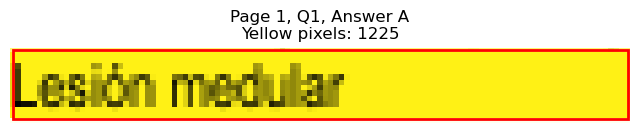

Page 1, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=127.0, y1=114.7
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 377
Page 1, Q1, B: Yellow percentage: 0.0%


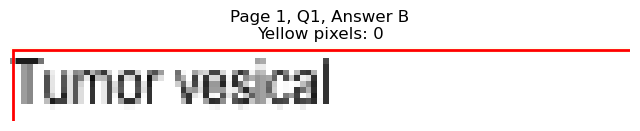

Page 1, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=387.8, y1=102.1
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 303
Page 1, Q1, C: Yellow percentage: 0.0%


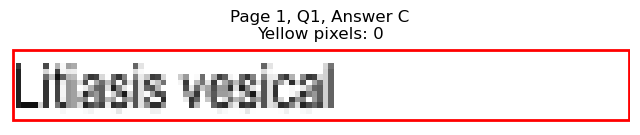

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=391.3, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 326
Page 1, Q1, D: Yellow percentage: 0.0%


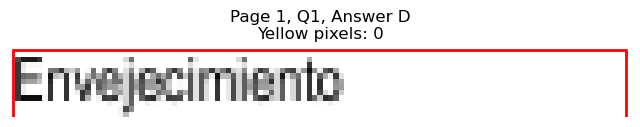


Page 1, Q1 - Selected Answer: A (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=144.0, y1=177.8
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 387
Page 1, Q2, A: Yellow percentage: 0.0%


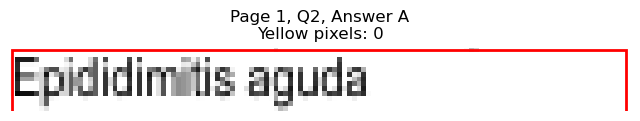

Page 1, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=109.0, y1=190.4
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 216
Page 1, Q2, B: Yellow percentage: 0.0%


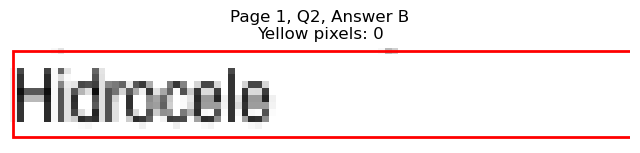

Page 1, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=398.7, y1=177.8
Page 1, Q2, C: Yellow pixels: 1321
Page 1, Q2, C: Total non-white pixels: 1586
Page 1, Q2, C: Yellow percentage: 83.3%


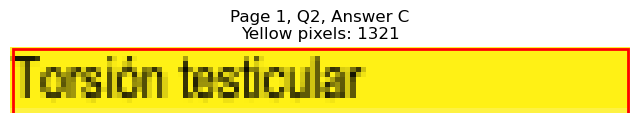

Page 1, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=398.8, y1=190.4
Page 1, Q2, D: Yellow pixels: 122
Page 1, Q2, D: Total non-white pixels: 489
Page 1, Q2, D: Yellow percentage: 24.9%


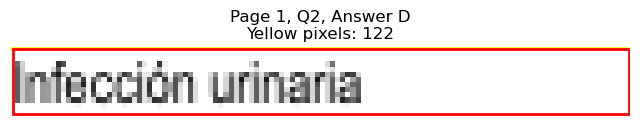


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=169.6, y1=228.3
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 487
Page 1, Q3, A: Yellow percentage: 0.0%


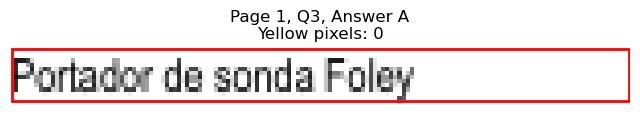

Page 1, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=133.6, y1=240.9
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 324
Page 1, Q3, B: Yellow percentage: 0.0%


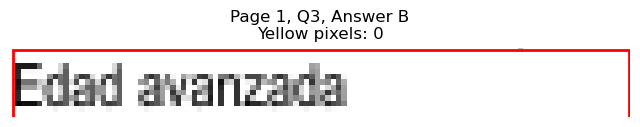

Page 1, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=398.2, y1=228.3
Page 1, Q3, C: Yellow pixels: 122
Page 1, Q3, C: Total non-white pixels: 479
Page 1, Q3, C: Yellow percentage: 25.5%


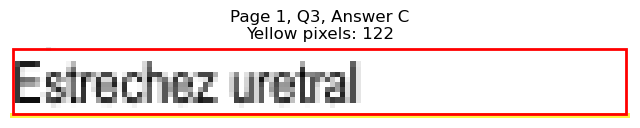

Page 1, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=397.3, y1=240.9
Page 1, Q3, D: Yellow pixels: 1311
Page 1, Q3, D: Total non-white pixels: 1573
Page 1, Q3, D: Yellow percentage: 83.3%


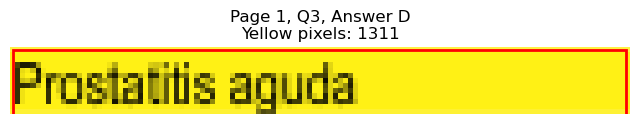


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=266.1, x1=114.5, y1=278.7
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 242
Page 1, Q4, A: Yellow percentage: 0.0%


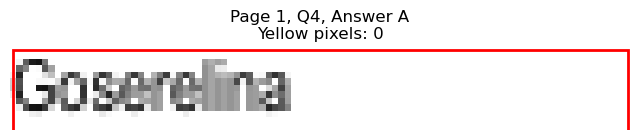

Page 1, Q4 - B: Detected box: x0=68.3, y0=278.8, x1=110.9, y1=291.5
Page 1, Q4, B: Yellow pixels: 1053
Page 1, Q4, B: Total non-white pixels: 1302
Page 1, Q4, B: Yellow percentage: 80.9%


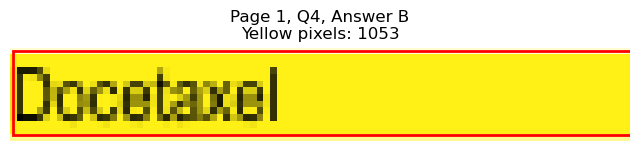

Page 1, Q4 - C: Detected box: x0=327.5, y0=266.1, x1=381.7, y1=278.7
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 285
Page 1, Q4, C: Yellow percentage: 0.0%


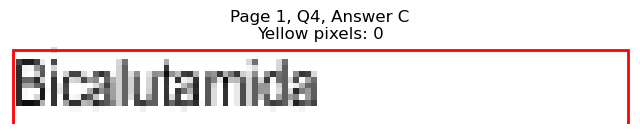

Page 1, Q4 - D: Detected box: x0=327.5, y0=278.8, x1=377.2, y1=291.5
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 267
Page 1, Q4, D: Yellow percentage: 0.0%


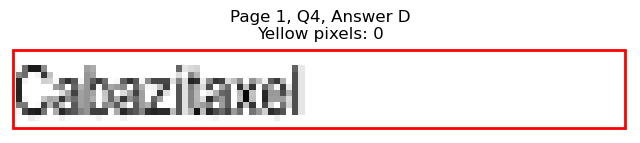


Page 1, Q4 - Selected Answer: B (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=316.6, x1=161.5, y1=329.3
Page 1, Q5, A: Yellow pixels: 144
Page 1, Q5, A: Total non-white pixels: 550
Page 1, Q5, A: Yellow percentage: 26.2%


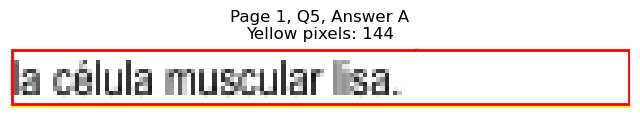

Page 1, Q5 - B: Detected box: x0=68.3, y0=329.2, x1=188.2, y1=341.9
Page 1, Q5, B: Yellow pixels: 1739
Page 1, Q5, B: Total non-white pixels: 2223
Page 1, Q5, B: Yellow percentage: 78.2%


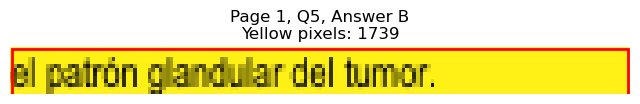

Page 1, Q5 - C: Detected box: x0=327.5, y0=316.6, x1=458.0, y1=329.3
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 671
Page 1, Q5, C: Yellow percentage: 0.0%


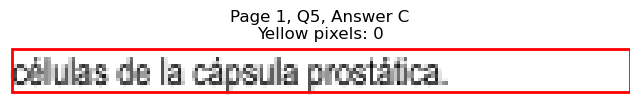

Page 1, Q5 - D: Detected box: x0=327.5, y0=329.2, x1=438.9, y1=341.9
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 560
Page 1, Q5, D: Yellow percentage: 0.0%


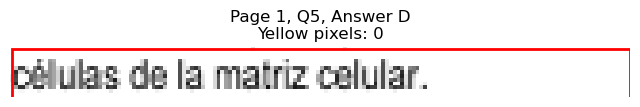


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=367.1, x1=122.4, y1=379.8
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 275
Page 1, Q6, A: Yellow percentage: 0.0%


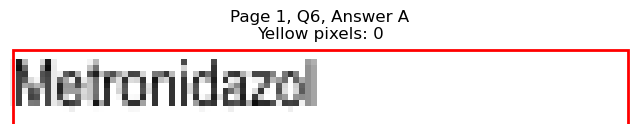

Page 1, Q6 - B: Detected box: x0=68.3, y0=379.7, x1=126.5, y1=392.4
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 318
Page 1, Q6, B: Yellow percentage: 0.0%


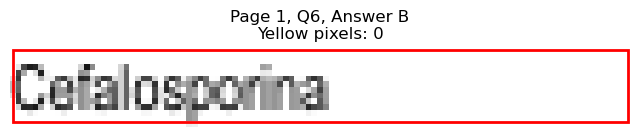

Page 1, Q6 - C: Detected box: x0=327.5, y0=367.1, x1=393.8, y1=379.8
Page 1, Q6, C: Yellow pixels: 1
Page 1, Q6, C: Total non-white pixels: 468
Page 1, Q6, C: Yellow percentage: 0.2%


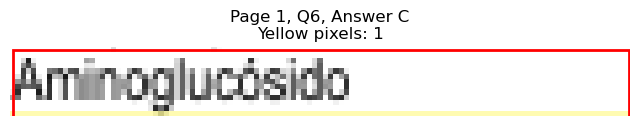

Page 1, Q6 - D: Detected box: x0=327.5, y0=379.7, x1=394.7, y1=392.4
Page 1, Q6, D: Yellow pixels: 1132
Page 1, Q6, D: Total non-white pixels: 1652
Page 1, Q6, D: Yellow percentage: 68.5%


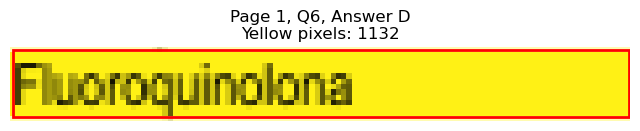


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=442.8, x1=157.6, y1=455.5
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 483
Page 1, Q7, A: Yellow percentage: 0.0%


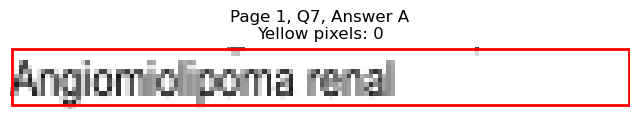

Page 1, Q7 - B: Detected box: x0=68.3, y0=455.5, x1=142.6, y1=468.1
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 381
Page 1, Q7, B: Yellow percentage: 0.0%


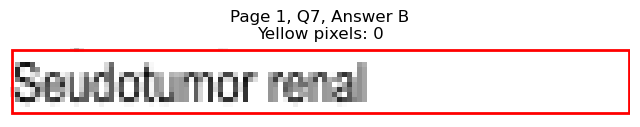

Page 1, Q7 - C: Detected box: x0=327.5, y0=442.8, x1=409.4, y1=455.5
Page 1, Q7, C: Yellow pixels: 133
Page 1, Q7, C: Total non-white pixels: 552
Page 1, Q7, C: Yellow percentage: 24.1%


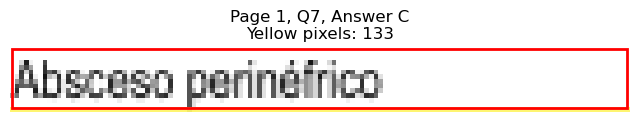

Page 1, Q7 - D: Detected box: x0=327.5, y0=455.5, x1=381.7, y1=468.1
Page 1, Q7, D: Yellow pixels: 1146
Page 1, Q7, D: Total non-white pixels: 1470
Page 1, Q7, D: Yellow percentage: 78.0%


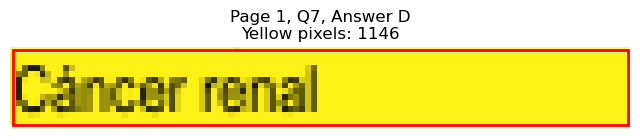


Page 1, Q7 - Selected Answer: D (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=493.4, x1=141.0, y1=506.0
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 388
Page 1, Q8, A: Yellow percentage: 0.0%


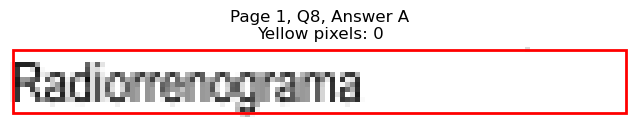

Page 1, Q8 - B: Detected box: x0=68.3, y0=506.0, x1=150.5, y1=518.6
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 433
Page 1, Q8, B: Yellow percentage: 0.0%


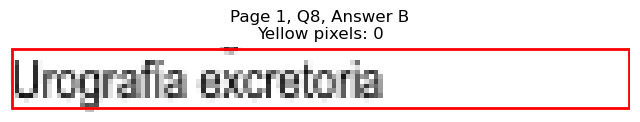

Page 1, Q8 - C: Detected box: x0=327.5, y0=493.4, x1=373.7, y1=506.0
Page 1, Q8, C: Yellow pixels: 97
Page 1, Q8, C: Total non-white pixels: 441
Page 1, Q8, C: Yellow percentage: 22.0%


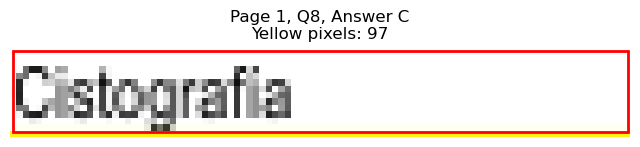

Page 1, Q8 - D: Detected box: x0=327.5, y0=506.0, x1=359.6, y1=518.6
Page 1, Q8, D: Yellow pixels: 958
Page 1, Q8, D: Total non-white pixels: 1162
Page 1, Q8, D: Yellow percentage: 82.4%


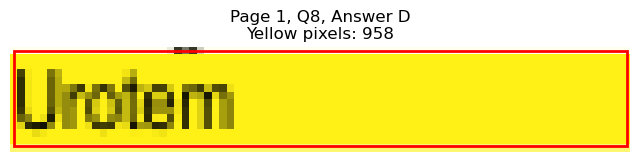


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=543.8, x1=119.9, y1=556.4
Page 1, Q9, A: Yellow pixels: 0
Page 1, Q9, A: Total non-white pixels: 285
Page 1, Q9, A: Yellow percentage: 0.0%


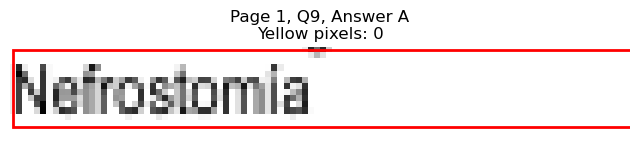

Page 1, Q9 - B: Detected box: x0=68.3, y0=556.5, x1=139.5, y1=569.2
Page 1, Q9, B: Yellow pixels: 1288
Page 1, Q9, B: Total non-white pixels: 1708
Page 1, Q9, B: Yellow percentage: 75.4%


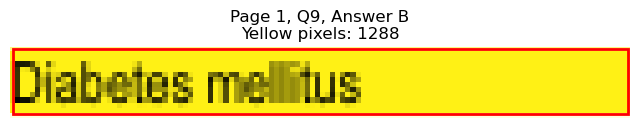

Page 1, Q9 - C: Detected box: x0=327.5, y0=543.8, x1=386.7, y1=556.4
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 317
Page 1, Q9, C: Yellow percentage: 0.0%


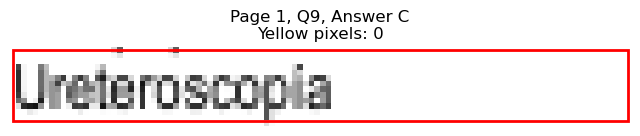

Page 1, Q9 - D: Detected box: x0=327.5, y0=556.5, x1=399.2, y1=569.2
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 409
Page 1, Q9, D: Yellow percentage: 0.0%


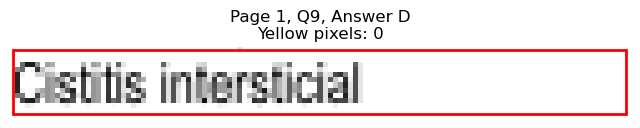


Page 1, Q9 - Selected Answer: B (based on yellow pixel count)




Page 1, Q10 - A: Detected box: x0=68.3, y0=594.3, x1=98.4, y1=607.0
Page 1, Q10, A: Yellow pixels: 951
Page 1, Q10, A: Total non-white pixels: 1053
Page 1, Q10, A: Yellow percentage: 90.3%


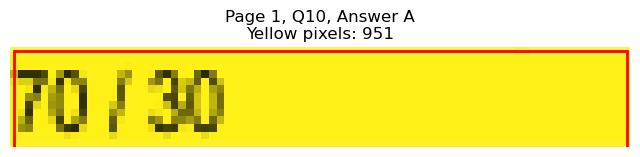

Page 1, Q10 - B: Detected box: x0=68.3, y0=606.9, x1=98.4, y1=619.6
Page 1, Q10, B: Yellow pixels: 81
Page 1, Q10, B: Total non-white pixels: 213
Page 1, Q10, B: Yellow percentage: 38.0%


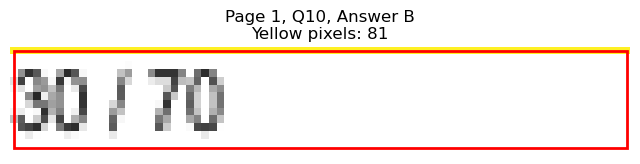

Page 1, Q10 - C: Detected box: x0=327.5, y0=594.3, x1=357.7, y1=607.0
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 140
Page 1, Q10, C: Yellow percentage: 0.0%


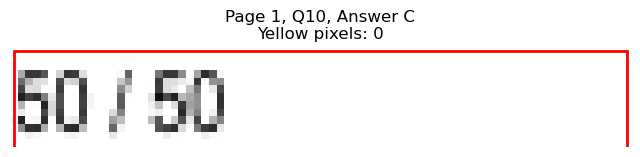

Page 1, Q10 - D: Detected box: x0=327.5, y0=606.9, x1=357.7, y1=619.6
Page 1, Q10, D: Yellow pixels: 0
Page 1, Q10, D: Total non-white pixels: 126
Page 1, Q10, D: Yellow percentage: 0.0%


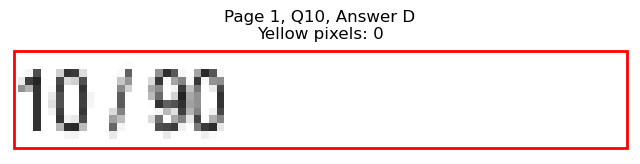


Page 1, Q10 - Selected Answer: A (based on yellow pixel count)




Page 1, Q11 - A: Detected box: x0=68.3, y0=657.5, x1=161.5, y1=670.1
Page 1, Q11, A: Yellow pixels: 0
Page 1, Q11, A: Total non-white pixels: 477
Page 1, Q11, A: Yellow percentage: 0.0%


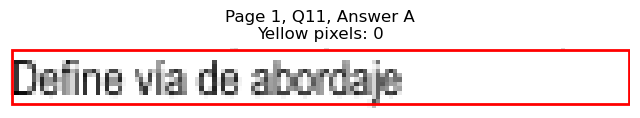

Page 1, Q11 - B: Detected box: x0=68.3, y0=670.1, x1=226.2, y1=682.7
Page 1, Q11, B: Yellow pixels: 0
Page 1, Q11, B: Total non-white pixels: 806
Page 1, Q11, B: Yellow percentage: 0.0%


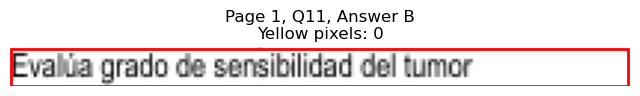

Page 1, Q11 - C: Detected box: x0=327.5, y0=657.5, x1=412.7, y1=670.1
Page 1, Q11, C: Yellow pixels: 136
Page 1, Q11, C: Total non-white pixels: 570
Page 1, Q11, C: Yellow percentage: 23.9%


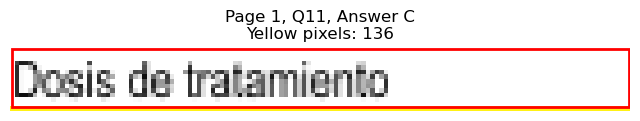

Page 1, Q11 - D: Detected box: x0=327.5, y0=670.1, x1=400.3, y1=682.7
Page 1, Q11, D: Yellow pixels: 1311
Page 1, Q11, D: Total non-white pixels: 1612
Page 1, Q11, D: Yellow percentage: 81.3%


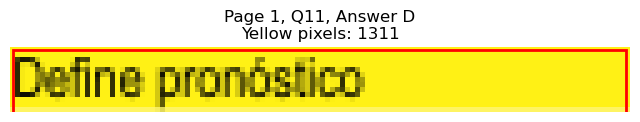


Page 1, Q11 - Selected Answer: D (based on yellow pixel count)




Page 1, Q12 - A: Detected box: x0=68.3, y0=708.0, x1=134.3, y1=720.6
Page 1, Q12, A: Yellow pixels: 117
Page 1, Q12, A: Total non-white pixels: 448
Page 1, Q12, A: Yellow percentage: 26.1%


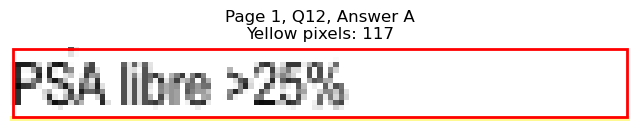

Page 1, Q12 - B: Detected box: x0=68.3, y0=720.6, x1=165.1, y1=733.2
Page 1, Q12, B: Yellow pixels: 1571
Page 1, Q12, B: Total non-white pixels: 2072
Page 1, Q12, B: Yellow percentage: 75.8%


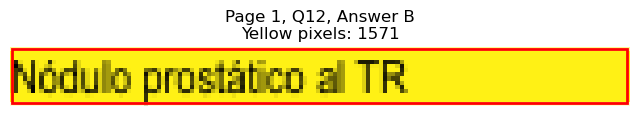

Page 1, Q12 - C: Detected box: x0=327.5, y0=708.0, x1=470.7, y1=720.6
Page 1, Q12, C: Yellow pixels: 0
Page 1, Q12, C: Total non-white pixels: 713
Page 1, Q12, C: Yellow percentage: 0.0%


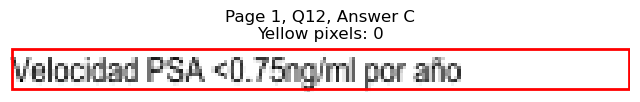

Page 1, Q12 - D: Detected box: x0=327.5, y0=720.6, x1=412.8, y1=733.2
Page 1, Q12, D: Yellow pixels: 0
Page 1, Q12, D: Total non-white pixels: 439
Page 1, Q12, D: Yellow percentage: 0.0%


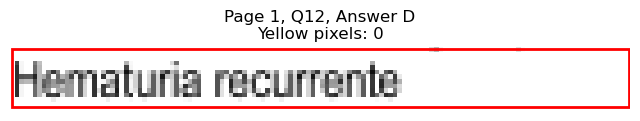


Page 1, Q12 - Selected Answer: B (based on yellow pixel count)





Page 2: Found 11 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=123.0, y1=102.1
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 262
Page 2, Q1, A: Yellow percentage: 0.0%


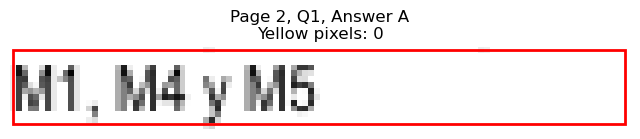

Page 2, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=123.0, y1=114.7
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 261
Page 2, Q1, B: Yellow percentage: 0.0%


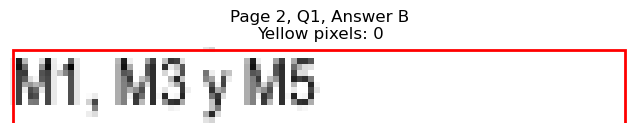

Page 2, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=382.3, y1=102.1
Page 2, Q1, C: Yellow pixels: 1190
Page 2, Q1, C: Total non-white pixels: 1484
Page 2, Q1, C: Yellow percentage: 80.2%


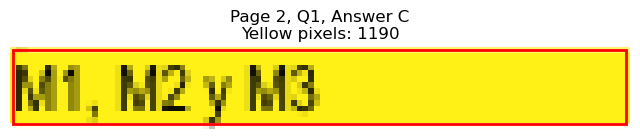

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=382.3, y1=114.7
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 383
Page 2, Q1, D: Yellow percentage: 0.0%


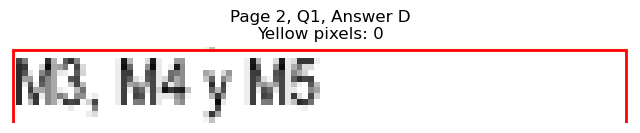


Page 2, Q1 - Selected Answer: C (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=56.6, y0=152.5, x1=65.2, y1=165.2
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 67
Page 2, Q2, A: Yellow percentage: 0.0%


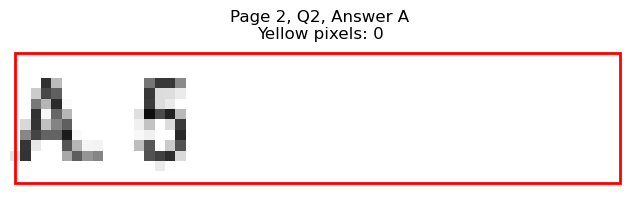

Page 2, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=80.9, y1=177.8
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 59
Page 2, Q2, B: Yellow percentage: 0.0%


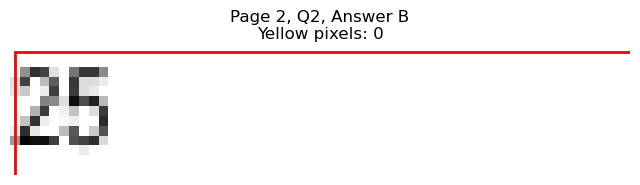

Page 2, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=340.1, y1=165.2
Page 2, Q2, C: Yellow pixels: 64
Page 2, Q2, C: Total non-white pixels: 125
Page 2, Q2, C: Yellow percentage: 51.2%


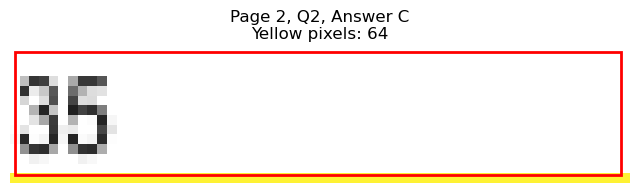

Page 2, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=340.1, y1=177.8
Page 2, Q2, D: Yellow pixels: 801
Page 2, Q2, D: Total non-white pixels: 832
Page 2, Q2, D: Yellow percentage: 96.3%


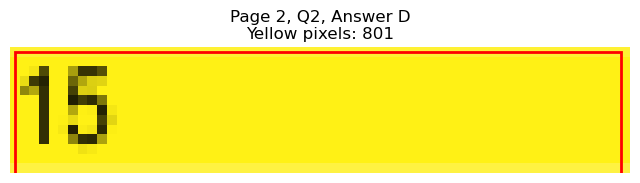


Page 2, Q2 - Selected Answer: D (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=117.5, y1=240.9
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 366
Page 2, Q3, A: Yellow percentage: 0.0%


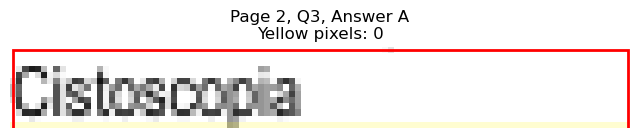

Page 2, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=114.5, y1=253.5
Page 2, Q3, B: Yellow pixels: 1060
Page 2, Q3, B: Total non-white pixels: 1358
Page 2, Q3, B: Yellow percentage: 78.1%


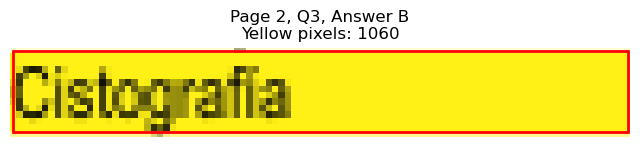

Page 2, Q3 - C: Detected box: x0=327.5, y0=228.3, x1=359.6, y1=240.9
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 159
Page 2, Q3, C: Yellow percentage: 0.0%


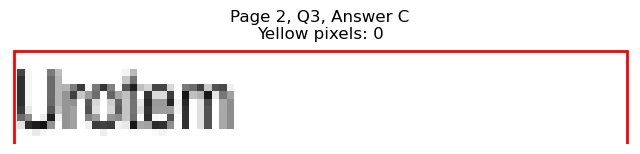

Page 2, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=421.9, y1=253.5
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 496
Page 2, Q3, D: Yellow percentage: 0.0%


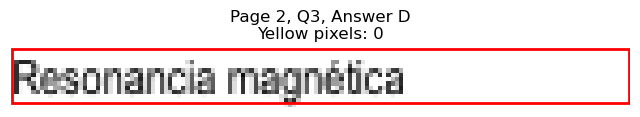


Page 2, Q3 - Selected Answer: B (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=111.4, y1=316.7
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 241
Page 2, Q4, A: Yellow percentage: 0.0%


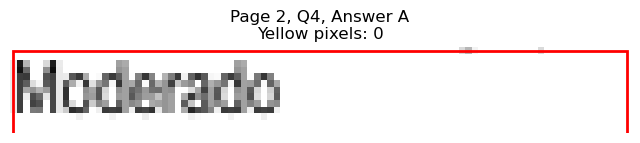

Page 2, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=86.4, y1=329.3
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 83
Page 2, Q4, B: Yellow percentage: 0.0%


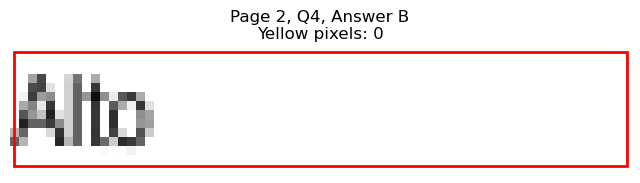

Page 2, Q4 - C: Detected box: x0=327.5, y0=304.0, x1=348.1, y1=316.7
Page 2, Q4, C: Yellow pixels: 859
Page 2, Q4, C: Total non-white pixels: 936
Page 2, Q4, C: Yellow percentage: 91.8%


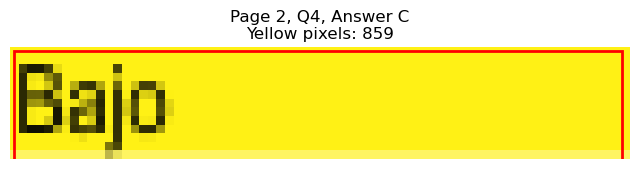

Page 2, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=348.7, y1=329.3
Page 2, Q4, D: Yellow pixels: 71
Page 2, Q4, D: Total non-white pixels: 177
Page 2, Q4, D: Yellow percentage: 40.1%


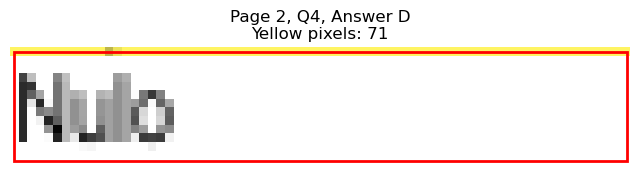


Page 2, Q4 - Selected Answer: C (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=118.9, y1=367.2
Page 2, Q5, A: Yellow pixels: 101
Page 2, Q5, A: Total non-white pixels: 351
Page 2, Q5, A: Yellow percentage: 28.8%


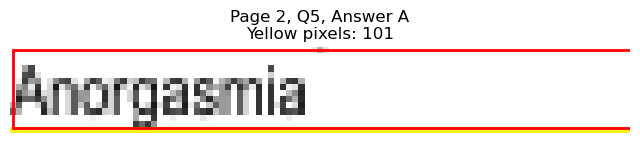

Page 2, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=148.1, y1=379.8
Page 2, Q5, B: Yellow pixels: 1406
Page 2, Q5, B: Total non-white pixels: 1703
Page 2, Q5, B: Yellow percentage: 82.6%


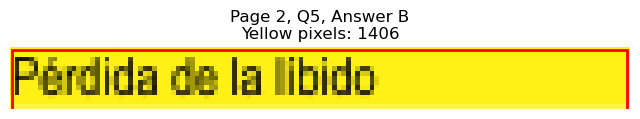

Page 2, Q5 - C: Detected box: x0=327.5, y0=354.5, x1=408.3, y1=367.2
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 402
Page 2, Q5, C: Yellow percentage: 0.0%


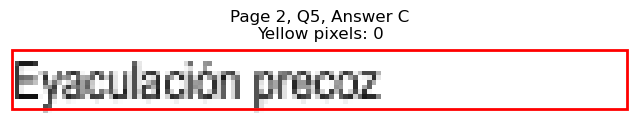

Page 2, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=393.8, y1=379.8
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 345
Page 2, Q5, D: Yellow percentage: 0.0%


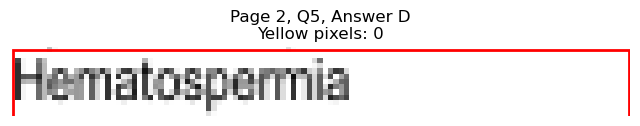


Page 2, Q5 - Selected Answer: B (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=417.6, x1=147.0, y1=430.3
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 358
Page 2, Q6, A: Yellow percentage: 0.0%


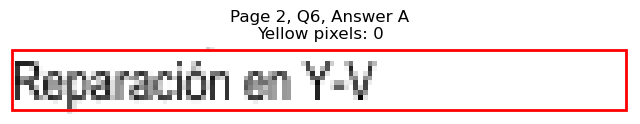

Page 2, Q6 - B: Detected box: x0=68.3, y0=430.2, x1=177.6, y1=442.9
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 579
Page 2, Q6, B: Yellow percentage: 0.0%


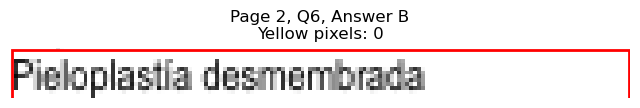

Page 2, Q6 - C: Detected box: x0=327.5, y0=417.6, x1=412.3, y1=430.3
Page 2, Q6, C: Yellow pixels: 136
Page 2, Q6, C: Total non-white pixels: 573
Page 2, Q6, C: Yellow percentage: 23.7%


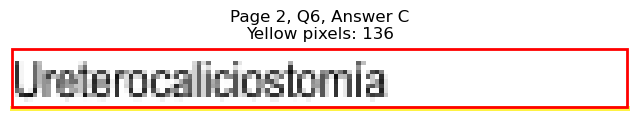

Page 2, Q6 - D: Detected box: x0=327.5, y0=430.2, x1=419.8, y1=442.9
Page 2, Q6, D: Yellow pixels: 1484
Page 2, Q6, D: Total non-white pixels: 1859
Page 2, Q6, D: Yellow percentage: 79.8%


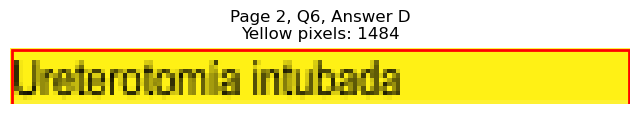


Page 2, Q6 - Selected Answer: D (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=493.4, x1=182.7, y1=506.0
Page 2, Q7, A: Yellow pixels: 1648
Page 2, Q7, A: Total non-white pixels: 2151
Page 2, Q7, A: Yellow percentage: 76.6%


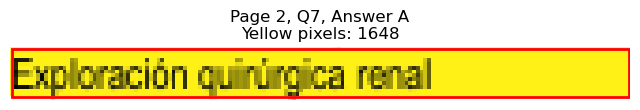

Page 2, Q7 - B: Detected box: x0=68.3, y0=506.0, x1=212.3, y1=518.6
Page 2, Q7, B: Yellow pixels: 188
Page 2, Q7, B: Total non-white pixels: 907
Page 2, Q7, B: Yellow percentage: 20.7%


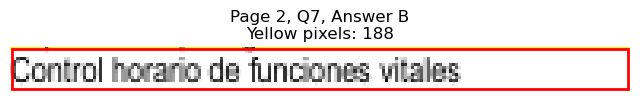

Page 2, Q7 - C: Detected box: x0=327.5, y0=493.4, x1=435.9, y1=506.0
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 549
Page 2, Q7, C: Yellow percentage: 0.0%


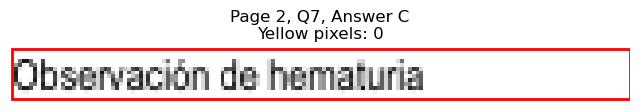

Page 2, Q7 - D: Detected box: x0=327.5, y0=506.0, x1=446.9, y1=518.6
Page 2, Q7, D: Yellow pixels: 0
Page 2, Q7, D: Total non-white pixels: 586
Page 2, Q7, D: Yellow percentage: 0.0%


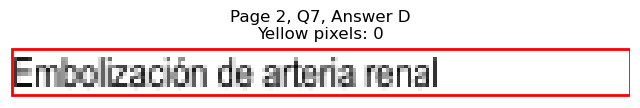


Page 2, Q7 - Selected Answer: A (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=556.5, x1=109.5, y1=569.2
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 208
Page 2, Q8, A: Yellow percentage: 0.0%


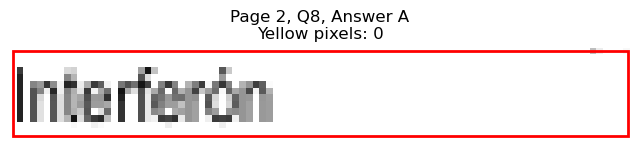

Page 2, Q8 - B: Detected box: x0=68.3, y0=569.1, x1=90.4, y1=581.8
Page 2, Q8, B: Yellow pixels: 0
Page 2, Q8, B: Total non-white pixels: 115
Page 2, Q8, B: Yellow percentage: 0.0%


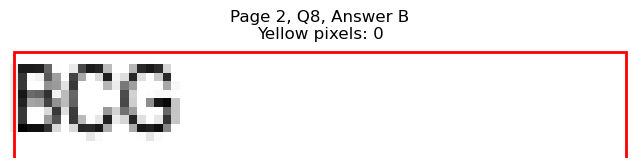

Page 2, Q8 - C: Detected box: x0=327.5, y0=556.5, x1=385.7, y1=569.2
Page 2, Q8, C: Yellow pixels: 109
Page 2, Q8, C: Total non-white pixels: 412
Page 2, Q8, C: Yellow percentage: 26.5%


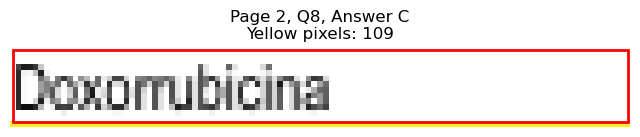

Page 2, Q8 - D: Detected box: x0=327.5, y0=569.1, x1=382.1, y1=581.8
Page 2, Q8, D: Yellow pixels: 1168
Page 2, Q8, D: Total non-white pixels: 1378
Page 2, Q8, D: Yellow percentage: 84.8%


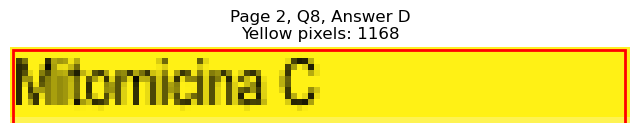


Page 2, Q8 - Selected Answer: D (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=606.9, x1=98.9, y1=619.6
Page 2, Q9, A: Yellow pixels: 946
Page 2, Q9, A: Total non-white pixels: 1134
Page 2, Q9, A: Yellow percentage: 83.4%


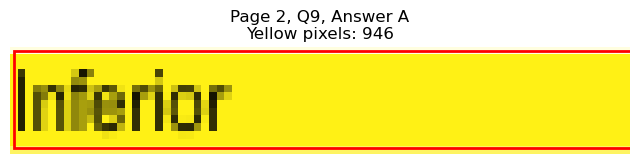

Page 2, Q9 - B: Detected box: x0=68.3, y0=619.6, x1=104.9, y1=632.3
Page 2, Q9, B: Yellow pixels: 87
Page 2, Q9, B: Total non-white pixels: 265
Page 2, Q9, B: Yellow percentage: 32.8%


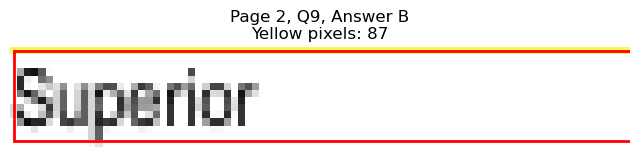

Page 2, Q9 - C: Detected box: x0=327.5, y0=606.9, x1=356.7, y1=619.6
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 164
Page 2, Q9, C: Yellow percentage: 0.0%


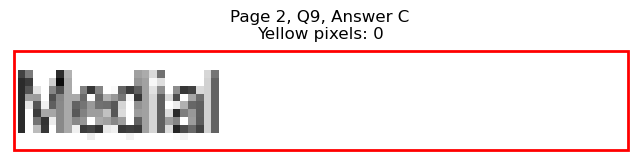

Page 2, Q9 - D: Detected box: x0=327.5, y0=619.6, x1=357.7, y1=632.3
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 142
Page 2, Q9, D: Yellow percentage: 0.0%


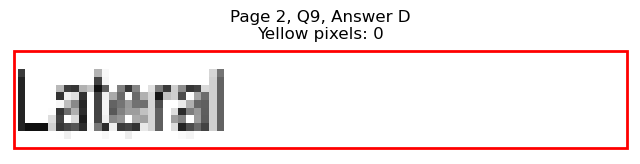


Page 2, Q9 - Selected Answer: A (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=68.3, y0=670.1, x1=112.0, y1=682.7
Page 2, Q10, A: Yellow pixels: 0
Page 2, Q10, A: Total non-white pixels: 293
Page 2, Q10, A: Yellow percentage: 0.0%


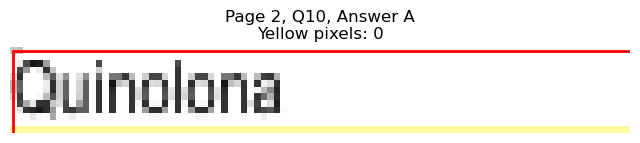

Page 2, Q10 - B: Detected box: x0=68.3, y0=682.7, x1=126.5, y1=695.3
Page 2, Q10, B: Yellow pixels: 1050
Page 2, Q10, B: Total non-white pixels: 1526
Page 2, Q10, B: Yellow percentage: 68.8%


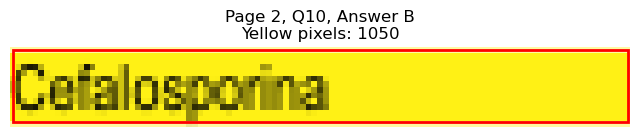

Page 2, Q10 - C: Detected box: x0=327.5, y0=670.1, x1=371.2, y1=682.7
Page 2, Q10, C: Yellow pixels: 0
Page 2, Q10, C: Total non-white pixels: 229
Page 2, Q10, C: Yellow percentage: 0.0%


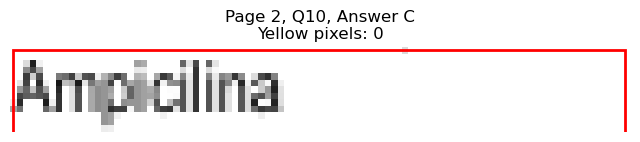

Page 2, Q10 - D: Detected box: x0=327.5, y0=682.7, x1=381.7, y1=695.3
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 266
Page 2, Q10, D: Yellow percentage: 0.0%


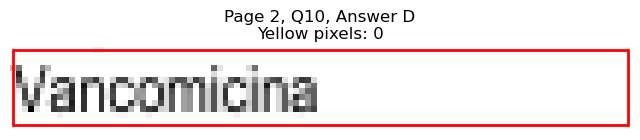


Page 2, Q10 - Selected Answer: B (based on yellow pixel count)




Page 2, Q11 - A: Detected box: x0=68.3, y0=733.2, x1=116.9, y1=745.8
Page 2, Q11, A: Yellow pixels: 1
Page 2, Q11, A: Total non-white pixels: 333
Page 2, Q11, A: Yellow percentage: 0.3%


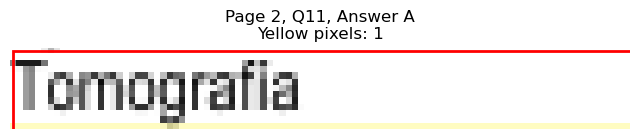

Page 2, Q11 - B: Detected box: x0=68.3, y0=240.9, x1=114.5, y1=253.5
Page 2, Q11, B: Yellow pixels: 1060
Page 2, Q11, B: Total non-white pixels: 1358
Page 2, Q11, B: Yellow percentage: 78.1%


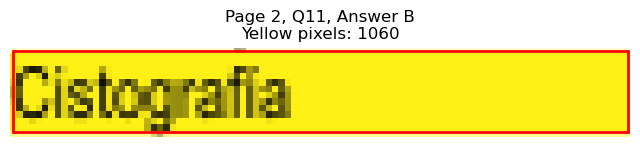

Page 2, Q11 - C: Detected box: x0=327.5, y0=733.2, x1=426.3, y1=745.8
Page 2, Q11, C: Yellow pixels: 0
Page 2, Q11, C: Total non-white pixels: 498
Page 2, Q11, C: Yellow percentage: 0.0%


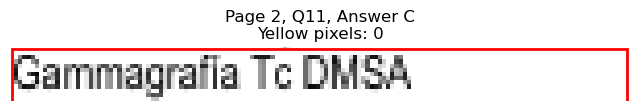

Page 2, Q11 - D: Detected box: x0=327.5, y0=240.9, x1=377.8, y1=253.5
Page 2, Q11, D: Yellow pixels: 0
Page 2, Q11, D: Total non-white pixels: 496
Page 2, Q11, D: Yellow percentage: 0.0%


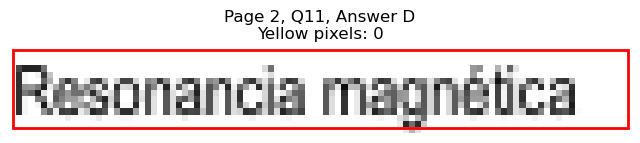


Page 2, Q11 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 11 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=110.9, y1=114.7
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 216
Page 3, Q1, A: Yellow percentage: 0.0%


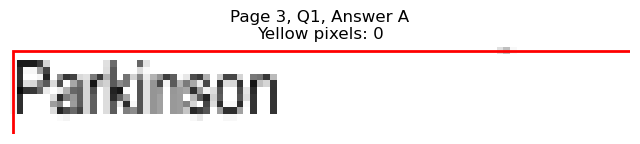

Page 3, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=156.6, y1=127.3
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 433
Page 3, Q1, B: Yellow percentage: 0.0%


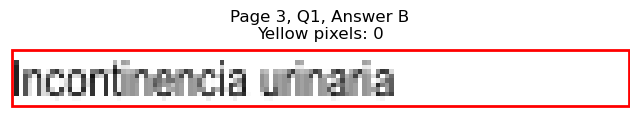

Page 3, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=402.8, y1=114.7
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 513
Page 3, Q1, C: Yellow percentage: 0.0%


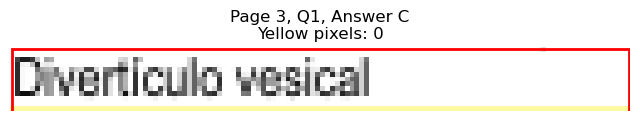

Page 3, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=371.7, y1=127.3
Page 3, Q1, D: Yellow pixels: 956
Page 3, Q1, D: Total non-white pixels: 1330
Page 3, Q1, D: Yellow percentage: 71.9%


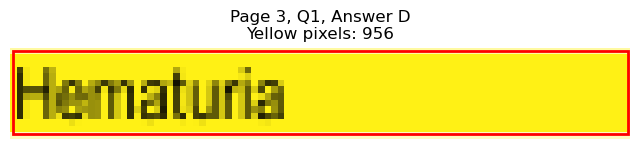


Page 3, Q1 - Selected Answer: D (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=147.0, y1=177.8
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 514
Page 3, Q2, A: Yellow percentage: 0.0%


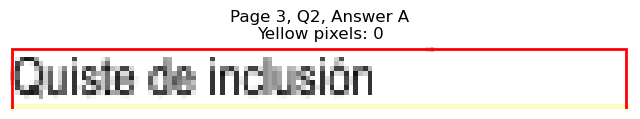

Page 3, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=172.6, y1=190.4
Page 3, Q2, B: Yellow pixels: 1422
Page 3, Q2, B: Total non-white pixels: 2170
Page 3, Q2, B: Yellow percentage: 65.5%


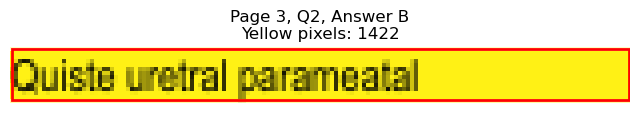

Page 3, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=425.8, y1=177.8
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 493
Page 3, Q2, C: Yellow percentage: 0.0%


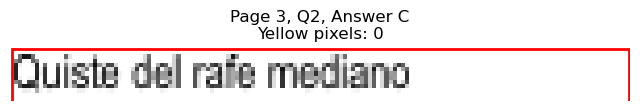

Page 3, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=434.9, y1=190.4
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 542
Page 3, Q2, D: Yellow percentage: 0.0%


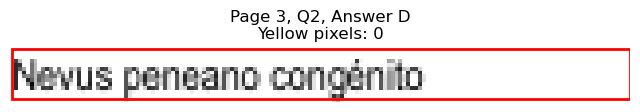


Page 3, Q2 - Selected Answer: B (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=106.9, y1=240.9
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 272
Page 3, Q3, A: Yellow percentage: 0.0%


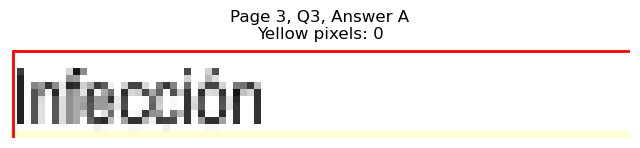

Page 3, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=130.9, y1=253.5
Page 3, Q3, B: Yellow pixels: 1235
Page 3, Q3, B: Total non-white pixels: 1582
Page 3, Q3, B: Yellow percentage: 78.1%


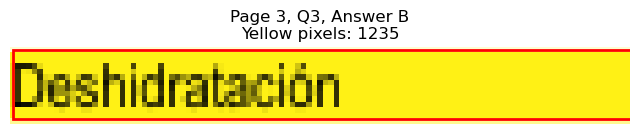

Page 3, Q3 - C: Detected box: x0=327.5, y0=228.3, x1=365.8, y1=240.9
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 177
Page 3, Q3, C: Yellow percentage: 0.0%


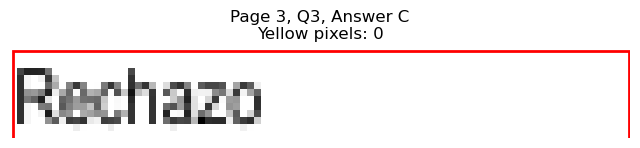

Page 3, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=378.2, y1=253.5
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 246
Page 3, Q3, D: Yellow percentage: 0.0%


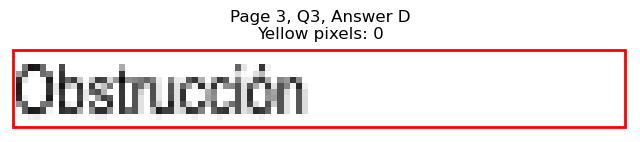


Page 3, Q3 - Selected Answer: B (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=181.1, y1=304.1
Page 3, Q4, A: Yellow pixels: 164
Page 3, Q4, A: Total non-white pixels: 756
Page 3, Q4, A: Yellow percentage: 21.7%


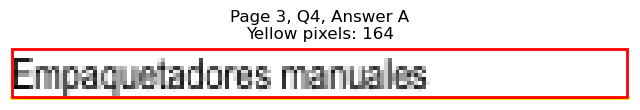

Page 3, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=163.6, y1=316.7
Page 3, Q4, B: Yellow pixels: 1486
Page 3, Q4, B: Total non-white pixels: 1898
Page 3, Q4, B: Yellow percentage: 78.3%


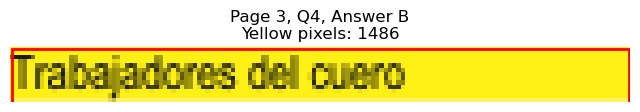

Page 3, Q4 - C: Detected box: x0=327.5, y0=291.4, x1=373.6, y1=304.1
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 228
Page 3, Q4, C: Yellow percentage: 0.0%


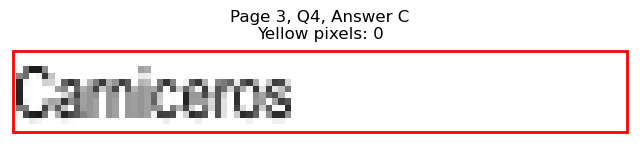

Page 3, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=411.8, y1=316.7
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 431
Page 3, Q4, D: Yellow percentage: 0.0%


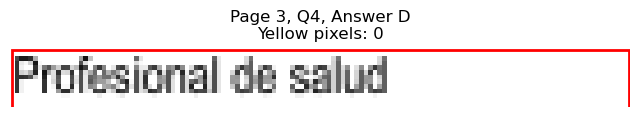


Page 3, Q4 - Selected Answer: B (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=341.9, x1=295.6, y1=354.6
Page 3, Q5, A: Yellow pixels: 2697
Page 3, Q5, A: Total non-white pixels: 3892
Page 3, Q5, A: Yellow percentage: 69.3%


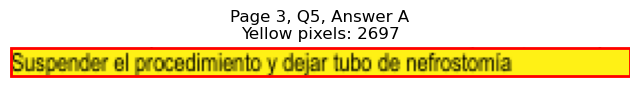

Page 3, Q5 - B: Detected box: x0=68.3, y0=354.5, x1=199.7, y1=367.2
Page 3, Q5, B: Yellow pixels: 180
Page 3, Q5, B: Total non-white pixels: 810
Page 3, Q5, B: Yellow percentage: 22.2%


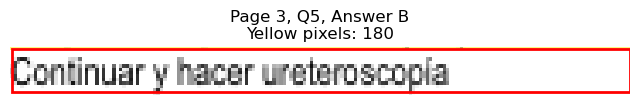

Page 3, Q5 - C: Detected box: x0=68.8, y0=367.1, x1=164.1, y1=379.8
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 467
Page 3, Q5, C: Yellow percentage: 0.0%


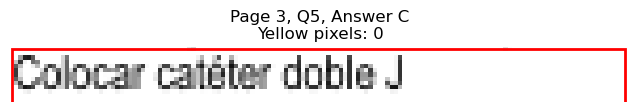

Page 3, Q5 - D: Detected box: x0=68.8, y0=379.7, x1=287.9, y1=392.4
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 1025
Page 3, Q5, D: Yellow percentage: 0.0%


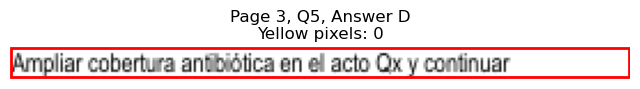


Page 3, Q5 - Selected Answer: A (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=417.6, x1=144.0, y1=430.3
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 387
Page 3, Q6, A: Yellow percentage: 0.0%


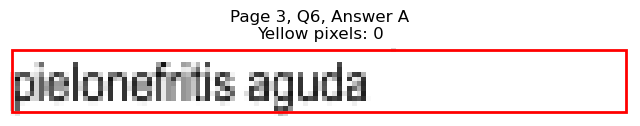

Page 3, Q6 - B: Detected box: x0=68.3, y0=430.2, x1=150.6, y1=442.9
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 415
Page 3, Q6, B: Yellow percentage: 0.0%


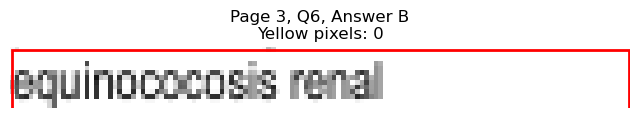

Page 3, Q6 - C: Detected box: x0=327.5, y0=417.6, x1=459.9, y1=430.3
Page 3, Q6, C: Yellow pixels: 1698
Page 3, Q6, C: Total non-white pixels: 2562
Page 3, Q6, C: Yellow percentage: 66.3%


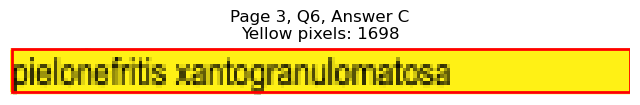

Page 3, Q6 - D: Detected box: x0=327.5, y0=430.2, x1=431.8, y1=442.9
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 700
Page 3, Q6, D: Yellow percentage: 0.0%


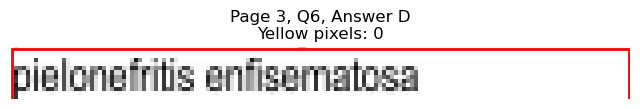


Page 3, Q6 - Selected Answer: C (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=468.1, x1=274.4, y1=480.7
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 986
Page 3, Q7, A: Yellow percentage: 0.0%


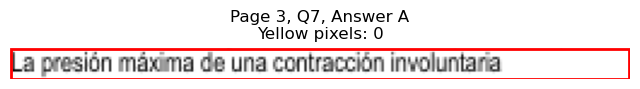

Page 3, Q7 - B: Detected box: x0=68.3, y0=480.8, x1=282.9, y1=493.4
Page 3, Q7, B: Yellow pixels: 265
Page 3, Q7, B: Total non-white pixels: 1288
Page 3, Q7, B: Yellow percentage: 20.6%


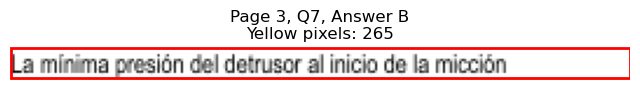

Page 3, Q7 - C: Detected box: x0=68.8, y0=493.4, x1=319.0, y1=506.0
Page 3, Q7, C: Yellow pixels: 3011
Page 3, Q7, C: Total non-white pixels: 3929
Page 3, Q7, C: Yellow percentage: 76.6%


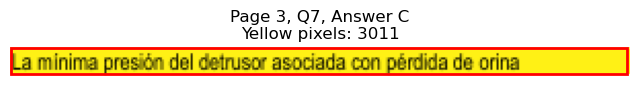

Page 3, Q7 - D: Detected box: x0=68.8, y0=506.0, x1=328.6, y1=518.6
Page 3, Q7, D: Yellow pixels: 308
Page 3, Q7, D: Total non-white pixels: 1562
Page 3, Q7, D: Yellow percentage: 19.7%


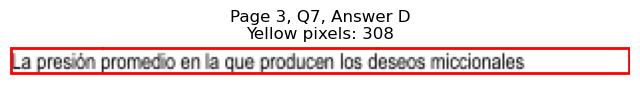


Page 3, Q7 - Selected Answer: C (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=543.8, x1=248.8, y1=556.4
Page 3, Q8, A: Yellow pixels: 2018
Page 3, Q8, A: Total non-white pixels: 2996
Page 3, Q8, A: Yellow percentage: 67.4%


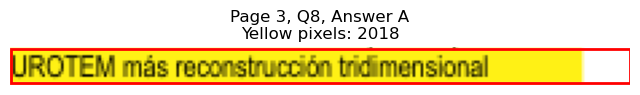

Page 3, Q8 - B: Detected box: x0=68.3, y0=556.5, x1=127.0, y1=569.2
Page 3, Q8, B: Yellow pixels: 109
Page 3, Q8, B: Total non-white pixels: 414
Page 3, Q8, B: Yellow percentage: 26.3%


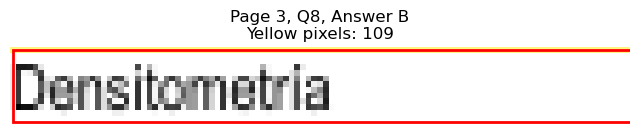

Page 3, Q8 - C: Detected box: x0=327.5, y0=543.8, x1=421.9, y1=556.4
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 492
Page 3, Q8, C: Yellow percentage: 0.0%


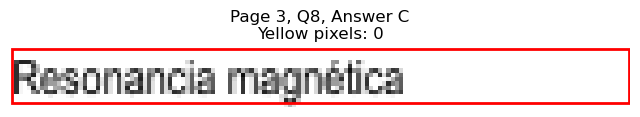

Page 3, Q8 - D: Detected box: x0=327.5, y0=556.5, x1=407.8, y1=569.2
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 418
Page 3, Q8, D: Yellow percentage: 0.0%


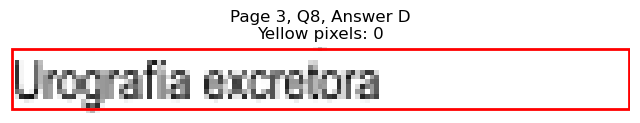


Page 3, Q8 - Selected Answer: A (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=606.9, x1=145.1, y1=619.6
Page 3, Q9, A: Yellow pixels: 0
Page 3, Q9, A: Total non-white pixels: 410
Page 3, Q9, A: Yellow percentage: 0.0%


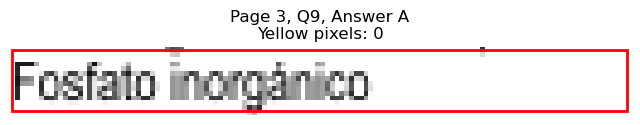

Page 3, Q9 - B: Detected box: x0=68.3, y0=619.6, x1=115.5, y1=632.3
Page 3, Q9, B: Yellow pixels: 0
Page 3, Q9, B: Total non-white pixels: 222
Page 3, Q9, B: Yellow percentage: 0.0%


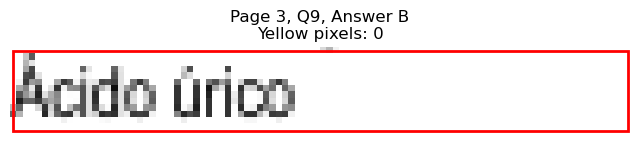

Page 3, Q9 - C: Detected box: x0=327.5, y0=606.9, x1=399.3, y1=619.6
Page 3, Q9, C: Yellow pixels: 1326
Page 3, Q9, C: Total non-white pixels: 1722
Page 3, Q9, C: Yellow percentage: 77.0%


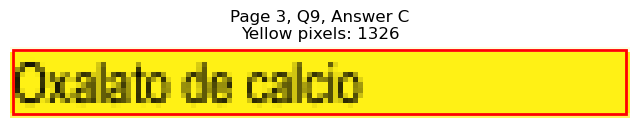

Page 3, Q9 - D: Detected box: x0=327.5, y0=619.6, x1=390.3, y1=632.3
Page 3, Q9, D: Yellow pixels: 114
Page 3, Q9, D: Total non-white pixels: 422
Page 3, Q9, D: Yellow percentage: 27.0%


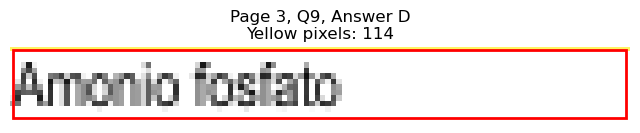


Page 3, Q9 - Selected Answer: C (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=68.3, y0=670.1, x1=267.9, y1=682.7
Page 3, Q10, A: Yellow pixels: 4
Page 3, Q10, A: Total non-white pixels: 1209
Page 3, Q10, A: Yellow percentage: 0.3%


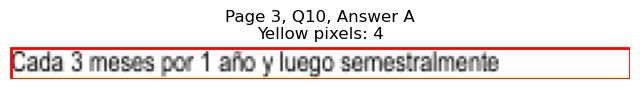

Page 3, Q10 - B: Detected box: x0=68.3, y0=682.7, x1=311.1, y1=695.3
Page 3, Q10, B: Yellow pixels: 2633
Page 3, Q10, B: Total non-white pixels: 4116
Page 3, Q10, B: Yellow percentage: 64.0%


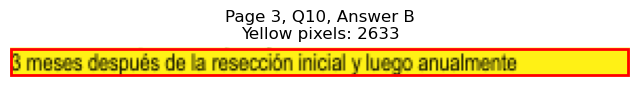

Page 3, Q10 - C: Detected box: x0=68.8, y0=695.4, x1=319.1, y1=708.0
Page 3, Q10, C: Yellow pixels: 4
Page 3, Q10, C: Total non-white pixels: 1579
Page 3, Q10, C: Yellow percentage: 0.3%


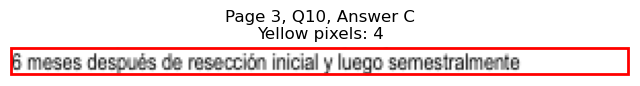

Page 3, Q10 - D: Detected box: x0=68.8, y0=708.0, x1=231.8, y1=720.6
Page 3, Q10, D: Yellow pixels: 0
Page 3, Q10, D: Total non-white pixels: 785
Page 3, Q10, D: Yellow percentage: 0.0%


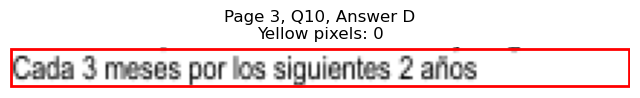


Page 3, Q10 - Selected Answer: B (based on yellow pixel count)




Page 3, Q11 - A: Detected box: x0=68.3, y0=745.8, x1=122.4, y1=758.4
Page 3, Q11, A: Yellow pixels: 1117
Page 3, Q11, A: Total non-white pixels: 1470
Page 3, Q11, A: Yellow percentage: 76.0%


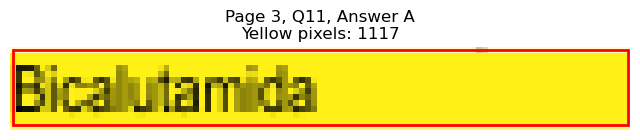

Page 3, Q11 - B: Detected box: x0=68.3, y0=758.5, x1=116.9, y1=771.2
Page 3, Q11, B: Yellow pixels: 99
Page 3, Q11, B: Total non-white pixels: 356
Page 3, Q11, B: Yellow percentage: 27.8%


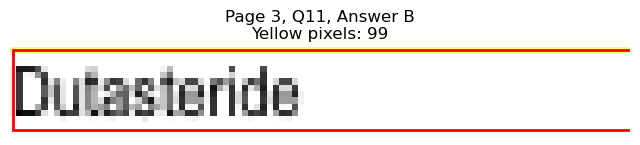

Page 3, Q11 - C: Detected box: x0=327.5, y0=745.8, x1=375.2, y1=758.4
Page 3, Q11, C: Yellow pixels: 0
Page 3, Q11, C: Total non-white pixels: 254
Page 3, Q11, C: Yellow percentage: 0.0%


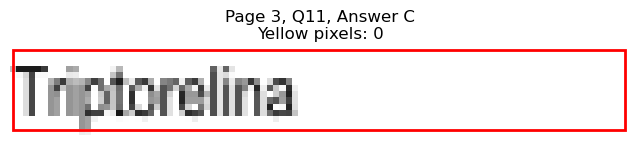

Page 3, Q11 - D: Detected box: x0=327.5, y0=758.5, x1=369.8, y1=771.2
Page 3, Q11, D: Yellow pixels: 0
Page 3, Q11, D: Total non-white pixels: 220
Page 3, Q11, D: Yellow percentage: 0.0%


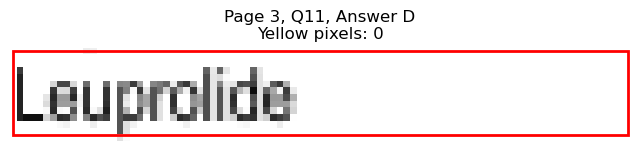


Page 3, Q11 - Selected Answer: A (based on yellow pixel count)





Page 4: Found 13 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=238.4, y1=102.1
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 867
Page 4, Q1, A: Yellow percentage: 0.0%


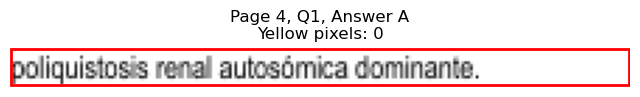

Page 4, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=229.8, y1=114.7
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 814
Page 4, Q1, B: Yellow percentage: 0.0%


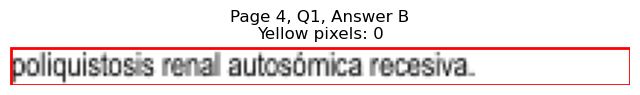

Page 4, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=410.3, y1=102.1
Page 4, Q1, C: Yellow pixels: 134
Page 4, Q1, C: Total non-white pixels: 552
Page 4, Q1, C: Yellow percentage: 24.3%


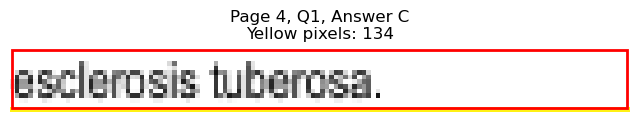

Page 4, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=405.3, y1=114.7
Page 4, Q1, D: Yellow pixels: 1392
Page 4, Q1, D: Total non-white pixels: 1677
Page 4, Q1, D: Yellow percentage: 83.0%


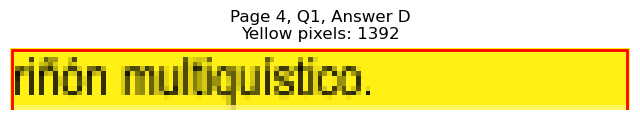


Page 4, Q1 - Selected Answer: D (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=144.5, y1=165.2
Page 4, Q2, A: Yellow pixels: 1373
Page 4, Q2, A: Total non-white pixels: 1778
Page 4, Q2, A: Yellow percentage: 77.2%


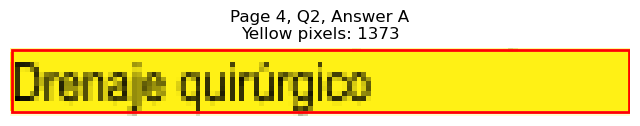

Page 4, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=156.1, y1=177.8
Page 4, Q2, B: Yellow pixels: 0
Page 4, Q2, B: Total non-white pixels: 590
Page 4, Q2, B: Yellow percentage: 0.0%


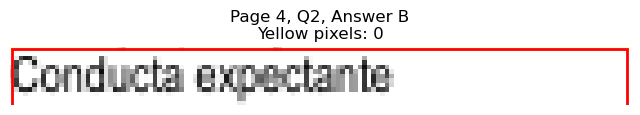

Page 4, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=381.7, y1=165.2
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 264
Page 4, Q2, C: Yellow percentage: 0.0%


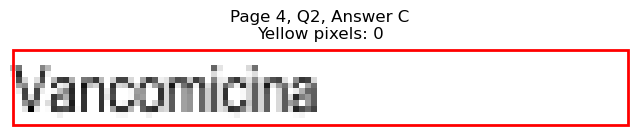

Page 4, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=438.9, y1=177.8
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 554
Page 4, Q2, D: Yellow percentage: 0.0%


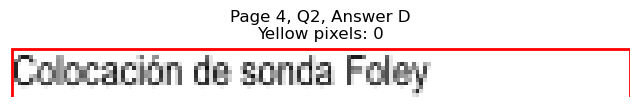


Page 4, Q2 - Selected Answer: A (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=202.9, x1=133.5, y1=215.6
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 326
Page 4, Q3, A: Yellow percentage: 0.0%


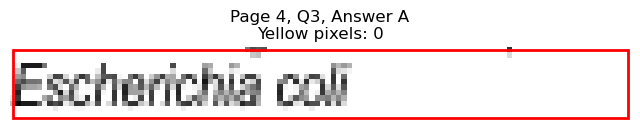

Page 4, Q3 - B: Detected box: x0=68.3, y0=215.7, x1=121.0, y1=228.3
Page 4, Q3, B: Yellow pixels: 1034
Page 4, Q3, B: Total non-white pixels: 1442
Page 4, Q3, B: Yellow percentage: 71.7%


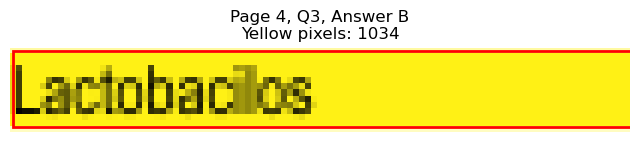

Page 4, Q3 - C: Detected box: x0=327.5, y0=202.9, x1=375.7, y1=215.6
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 247
Page 4, Q3, C: Yellow percentage: 0.0%


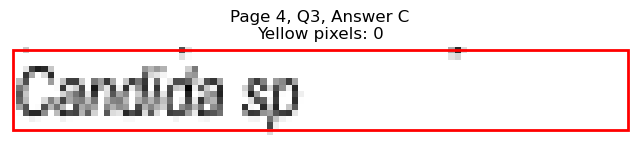

Page 4, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=374.7, y1=228.3
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 268
Page 4, Q3, D: Yellow percentage: 0.0%


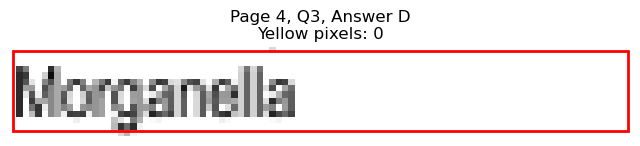


Page 4, Q3 - Selected Answer: B (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=253.5, x1=131.8, y1=266.1
Page 4, Q4, A: Yellow pixels: 114
Page 4, Q4, A: Total non-white pixels: 423
Page 4, Q4, A: Yellow percentage: 27.0%


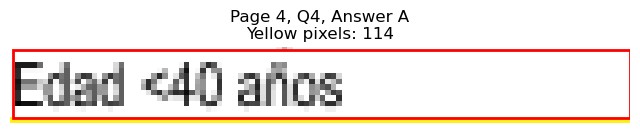

Page 4, Q4 - B: Detected box: x0=68.3, y0=266.1, x1=159.1, y1=278.7
Page 4, Q4, B: Yellow pixels: 1474
Page 4, Q4, B: Total non-white pixels: 1846
Page 4, Q4, B: Yellow percentage: 79.8%


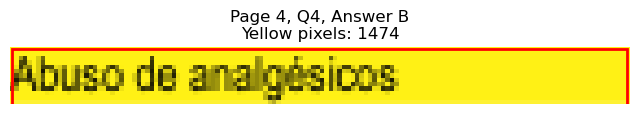

Page 4, Q4 - C: Detected box: x0=327.5, y0=253.5, x1=415.9, y1=266.1
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 454
Page 4, Q4, C: Yellow percentage: 0.0%


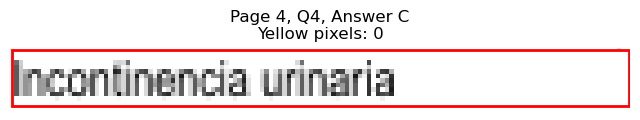

Page 4, Q4 - D: Detected box: x0=327.5, y0=266.1, x1=417.3, y1=278.7
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 454
Page 4, Q4, D: Yellow percentage: 0.0%


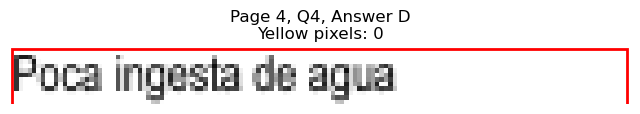


Page 4, Q4 - Selected Answer: B (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=304.0, x1=179.2, y1=316.7
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 523
Page 4, Q5, A: Yellow percentage: 0.0%


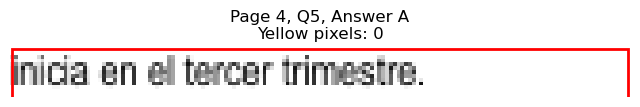

Page 4, Q5 - B: Detected box: x0=68.3, y0=316.6, x1=209.7, y1=329.3
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 724
Page 4, Q5, B: Yellow percentage: 0.0%


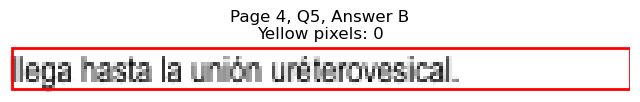

Page 4, Q5 - C: Detected box: x0=327.5, y0=304.0, x1=440.8, y1=316.7
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 723
Page 4, Q5, C: Yellow percentage: 0.0%


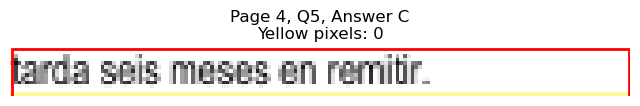

Page 4, Q5 - D: Detected box: x0=327.5, y0=316.6, x1=470.0, y1=329.3
Page 4, Q5, D: Yellow pixels: 1832
Page 4, Q5, D: Total non-white pixels: 2716
Page 4, Q5, D: Yellow percentage: 67.5%


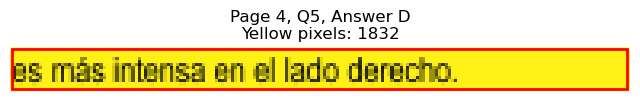


Page 4, Q5 - Selected Answer: D (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=354.5, x1=169.1, y1=367.2
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 505
Page 4, Q6, A: Yellow percentage: 0.0%


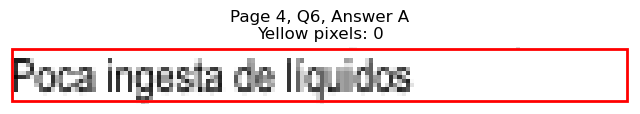

Page 4, Q6 - B: Detected box: x0=68.3, y0=367.1, x1=153.0, y1=379.8
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 407
Page 4, Q6, B: Yellow percentage: 0.0%


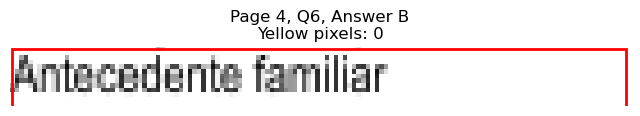

Page 4, Q6 - C: Detected box: x0=327.5, y0=354.5, x1=406.7, y1=367.2
Page 4, Q6, C: Yellow pixels: 130
Page 4, Q6, C: Total non-white pixels: 527
Page 4, Q6, C: Yellow percentage: 24.7%


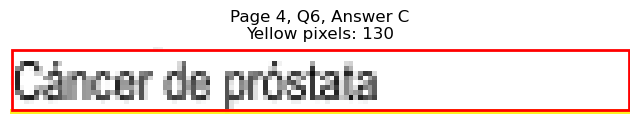

Page 4, Q6 - D: Detected box: x0=327.5, y0=367.1, x1=452.5, y1=379.8
Page 4, Q6, D: Yellow pixels: 1787
Page 4, Q6, D: Total non-white pixels: 2288
Page 4, Q6, D: Yellow percentage: 78.1%


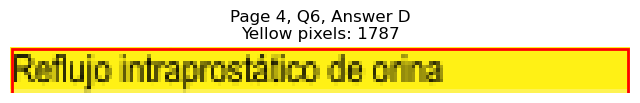


Page 4, Q6 - Selected Answer: D (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=404.9, x1=167.1, y1=417.6
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 497
Page 4, Q7, A: Yellow percentage: 0.0%


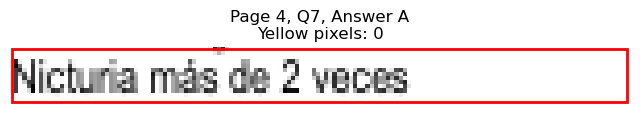

Page 4, Q7 - B: Detected box: x0=68.3, y0=417.6, x1=209.8, y1=430.3
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 710
Page 4, Q7, B: Yellow percentage: 0.0%


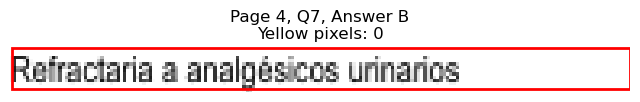

Page 4, Q7 - C: Detected box: x0=327.5, y0=404.9, x1=408.1, y1=417.6
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 383
Page 4, Q7, C: Yellow percentage: 0.0%


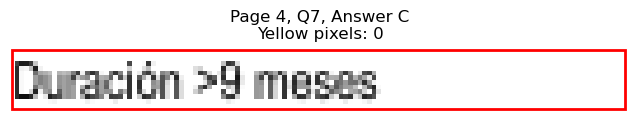

Page 4, Q7 - D: Detected box: x0=327.5, y0=417.6, x1=438.2, y1=430.3
Page 4, Q7, D: Yellow pixels: 1532
Page 4, Q7, D: Total non-white pixels: 2268
Page 4, Q7, D: Yellow percentage: 67.5%


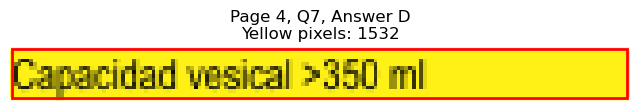


Page 4, Q7 - Selected Answer: D (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=455.5, x1=88.8, y1=468.1
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 94
Page 4, Q8, A: Yellow percentage: 0.0%


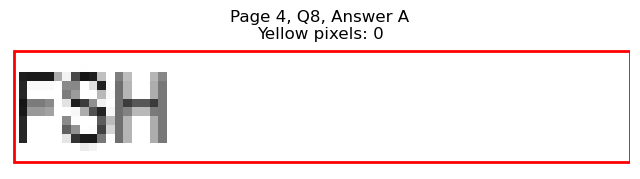

Page 4, Q8 - B: Detected box: x0=68.3, y0=468.1, x1=88.8, y1=480.7
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 95
Page 4, Q8, B: Yellow percentage: 0.0%


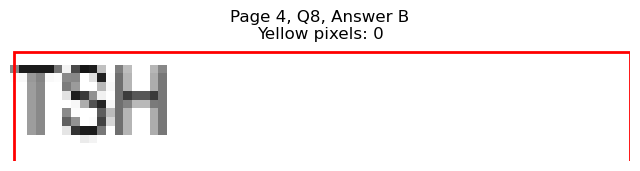

Page 4, Q8 - C: Detected box: x0=327.5, y0=455.5, x1=354.7, y1=468.1
Page 4, Q8, C: Yellow pixels: 78
Page 4, Q8, C: Total non-white pixels: 206
Page 4, Q8, C: Yellow percentage: 37.9%


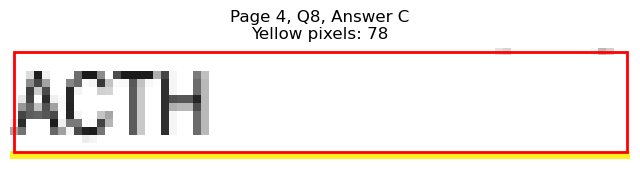

Page 4, Q8 - D: Detected box: x0=327.5, y0=468.1, x1=341.6, y1=480.7
Page 4, Q8, D: Yellow pixels: 803
Page 4, Q8, D: Total non-white pixels: 845
Page 4, Q8, D: Yellow percentage: 95.0%


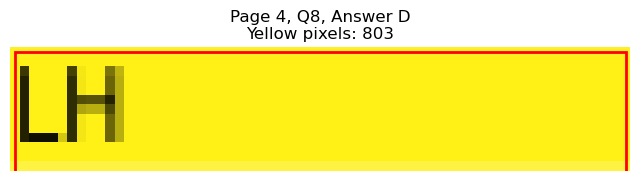


Page 4, Q8 - Selected Answer: D (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=506.0, x1=140.5, y1=518.6
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 352
Page 4, Q9, A: Yellow percentage: 0.0%


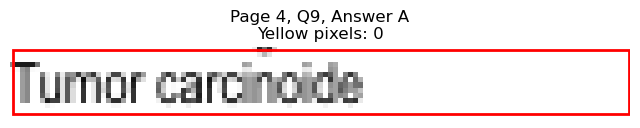

Page 4, Q9 - B: Detected box: x0=68.3, y0=518.6, x1=102.9, y1=531.2
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 165
Page 4, Q9, B: Yellow percentage: 0.0%


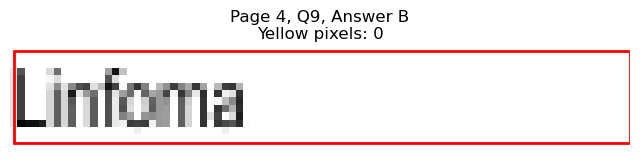

Page 4, Q9 - C: Detected box: x0=327.5, y0=506.0, x1=368.7, y1=518.6
Page 4, Q9, C: Yellow pixels: 1044
Page 4, Q9, C: Total non-white pixels: 1288
Page 4, Q9, C: Yellow percentage: 81.1%


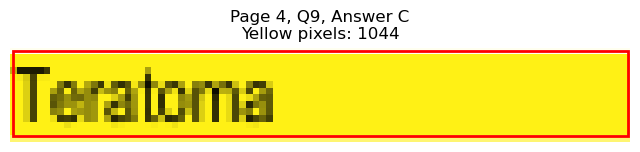

Page 4, Q9 - D: Detected box: x0=327.5, y0=518.6, x1=440.9, y1=531.2
Page 4, Q9, D: Yellow pixels: 164
Page 4, Q9, D: Total non-white pixels: 718
Page 4, Q9, D: Yellow percentage: 22.8%


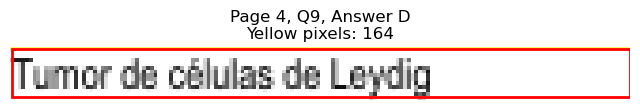


Page 4, Q9 - Selected Answer: C (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=68.3, y0=569.1, x1=141.5, y1=581.8
Page 4, Q10, A: Yellow pixels: 1339
Page 4, Q10, A: Total non-white pixels: 1612
Page 4, Q10, A: Yellow percentage: 83.1%


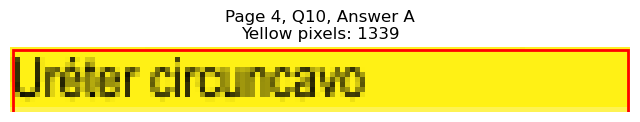

Page 4, Q10 - B: Detected box: x0=68.3, y0=581.7, x1=157.6, y1=594.4
Page 4, Q10, B: Yellow pixels: 140
Page 4, Q10, B: Total non-white pixels: 599
Page 4, Q10, B: Yellow percentage: 23.4%


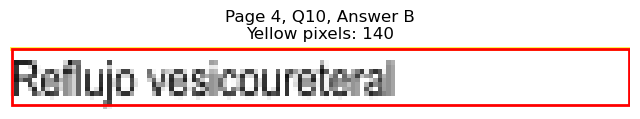

Page 4, Q10 - C: Detected box: x0=327.5, y0=569.1, x1=408.8, y1=581.8
Page 4, Q10, C: Yellow pixels: 0
Page 4, Q10, C: Total non-white pixels: 391
Page 4, Q10, C: Yellow percentage: 0.0%


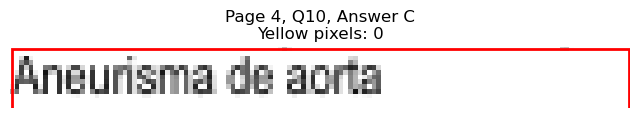

Page 4, Q10 - D: Detected box: x0=327.5, y0=581.7, x1=400.7, y1=594.4
Page 4, Q10, D: Yellow pixels: 0
Page 4, Q10, D: Total non-white pixels: 371
Page 4, Q10, D: Yellow percentage: 0.0%


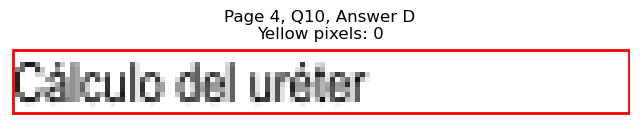


Page 4, Q10 - Selected Answer: A (based on yellow pixel count)




Page 4, Q11 - A: Detected box: x0=68.3, y0=632.2, x1=139.6, y1=644.9
Page 4, Q11, A: Yellow pixels: 0
Page 4, Q11, A: Total non-white pixels: 374
Page 4, Q11, A: Yellow percentage: 0.0%


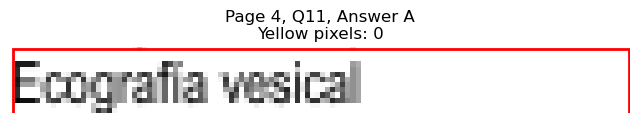

Page 4, Q11 - B: Detected box: x0=68.3, y0=644.9, x1=162.6, y1=657.5
Page 4, Q11, B: Yellow pixels: 0
Page 4, Q11, B: Total non-white pixels: 487
Page 4, Q11, B: Yellow percentage: 0.0%


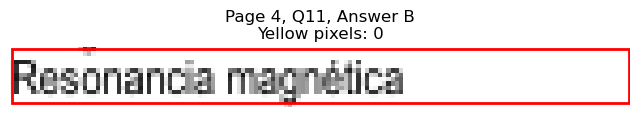

Page 4, Q11 - C: Detected box: x0=327.5, y0=632.2, x1=377.2, y1=644.9
Page 4, Q11, C: Yellow pixels: 0
Page 4, Q11, C: Total non-white pixels: 358
Page 4, Q11, C: Yellow percentage: 0.0%


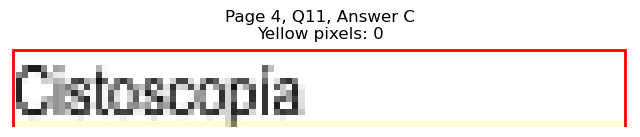

Page 4, Q11 - D: Detected box: x0=327.5, y0=644.9, x1=422.3, y1=657.5
Page 4, Q11, D: Yellow pixels: 1511
Page 4, Q11, D: Total non-white pixels: 2044
Page 4, Q11, D: Yellow percentage: 73.9%


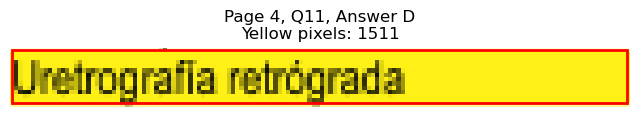


Page 4, Q11 - Selected Answer: D (based on yellow pixel count)




Page 4, Q12 - A: Detected box: x0=68.3, y0=682.7, x1=138.0, y1=695.3
Page 4, Q12, A: Yellow pixels: 0
Page 4, Q12, A: Total non-white pixels: 336
Page 4, Q12, A: Yellow percentage: 0.0%


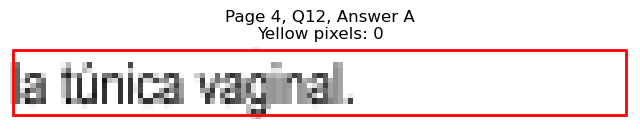

Page 4, Q12 - B: Detected box: x0=68.3, y0=695.4, x1=149.1, y1=708.0
Page 4, Q12, B: Yellow pixels: 1412
Page 4, Q12, B: Total non-white pixels: 1719
Page 4, Q12, B: Yellow percentage: 82.1%


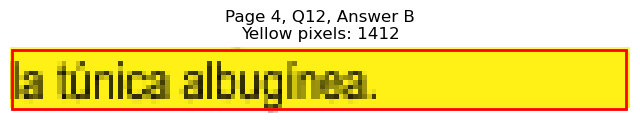

Page 4, Q12 - C: Detected box: x0=327.5, y0=682.7, x1=400.7, y1=695.3
Page 4, Q12, C: Yellow pixels: 0
Page 4, Q12, C: Total non-white pixels: 345
Page 4, Q12, C: Yellow percentage: 0.0%


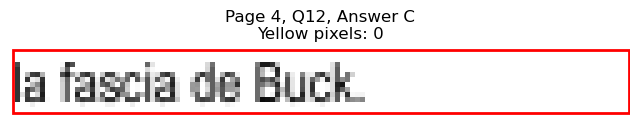

Page 4, Q12 - D: Detected box: x0=327.5, y0=695.4, x1=413.3, y1=708.0
Page 4, Q12, D: Yellow pixels: 0
Page 4, Q12, D: Total non-white pixels: 409
Page 4, Q12, D: Yellow percentage: 0.0%


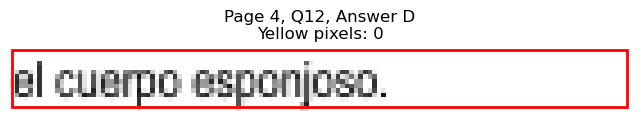


Page 4, Q12 - Selected Answer: B (based on yellow pixel count)




Page 4, Q13 - A: Detected box: x0=68.3, y0=745.8, x1=175.6, y1=758.4
Page 4, Q13, A: Yellow pixels: 0
Page 4, Q13, A: Total non-white pixels: 531
Page 4, Q13, A: Yellow percentage: 0.0%


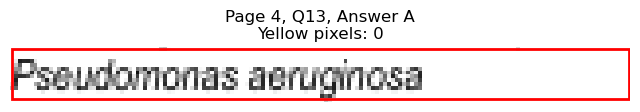

Page 4, Q13 - B: Detected box: x0=68.3, y0=758.5, x1=161.5, y1=771.2
Page 4, Q13, B: Yellow pixels: 0
Page 4, Q13, B: Total non-white pixels: 489
Page 4, Q13, B: Yellow percentage: 0.0%


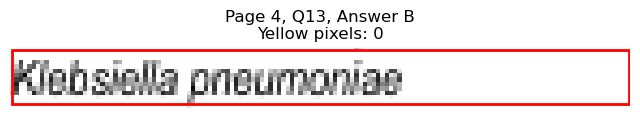

Page 4, Q13 - C: Detected box: x0=327.5, y0=745.8, x1=428.8, y1=758.4
Page 4, Q13, C: Yellow pixels: 0
Page 4, Q13, C: Total non-white pixels: 520
Page 4, Q13, C: Yellow percentage: 0.0%


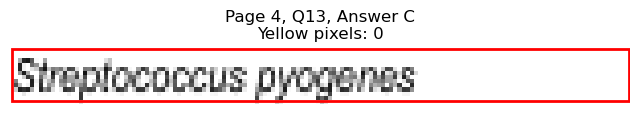

Page 4, Q13 - D: Detected box: x0=327.5, y0=758.5, x1=394.3, y1=771.2
Page 4, Q13, D: Yellow pixels: 1262
Page 4, Q13, D: Total non-white pixels: 1652
Page 4, Q13, D: Yellow percentage: 76.4%


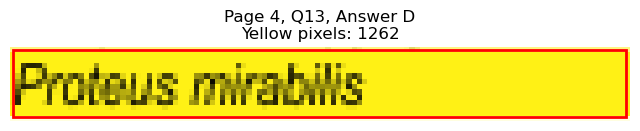


Page 4, Q13 - Selected Answer: D (based on yellow pixel count)





Page 5: Found 13 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=100.3, y1=127.3
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 155
Page 5, Q1, A: Yellow percentage: 0.0%


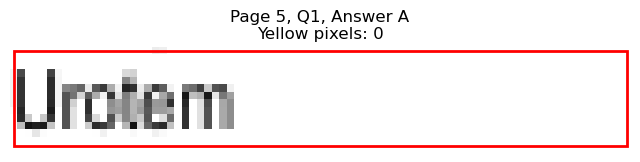

Page 5, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=148.6, y1=139.9
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 408
Page 5, Q1, B: Yellow percentage: 0.0%


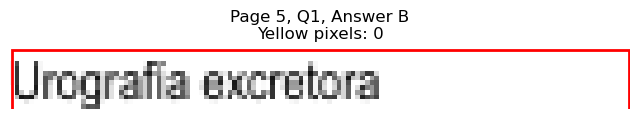

Page 5, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=431.8, y1=127.3
Page 5, Q1, C: Yellow pixels: 1474
Page 5, Q1, C: Total non-white pixels: 2170
Page 5, Q1, C: Yellow percentage: 67.9%


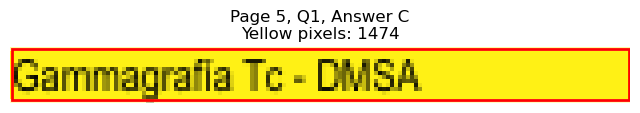

Page 5, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=396.8, y1=139.9
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 495
Page 5, Q1, D: Yellow percentage: 0.0%


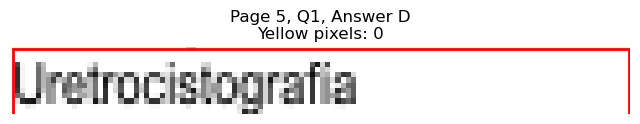


Page 5, Q1 - Selected Answer: C (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=141.5, y1=177.8
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 469
Page 5, Q2, A: Yellow percentage: 0.0%


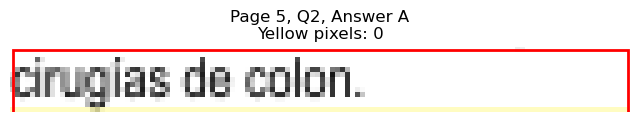

Page 5, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=134.5, y1=190.4
Page 5, Q2, B: Yellow pixels: 1155
Page 5, Q2, B: Total non-white pixels: 1638
Page 5, Q2, B: Yellow percentage: 70.5%


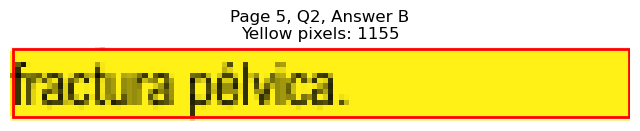

Page 5, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=400.7, y1=177.8
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 360
Page 5, Q2, C: Yellow percentage: 0.0%


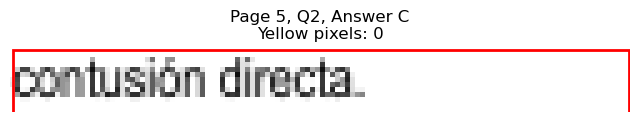

Page 5, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=409.3, y1=190.4
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 405
Page 5, Q2, D: Yellow percentage: 0.0%


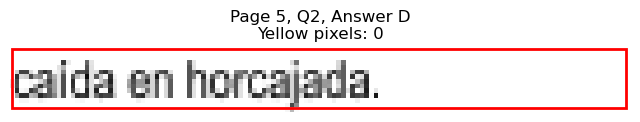


Page 5, Q2 - Selected Answer: B (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=106.5, y1=228.3
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 195
Page 5, Q3, A: Yellow percentage: 0.0%


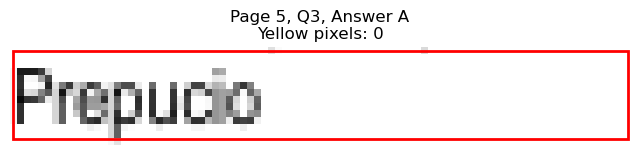

Page 5, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=98.9, y1=240.9
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 150
Page 5, Q3, B: Yellow percentage: 0.0%


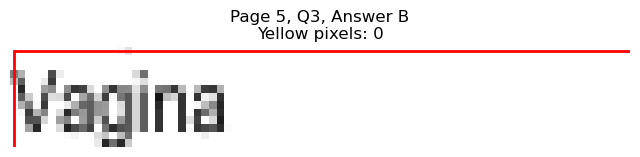

Page 5, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=388.7, y1=228.3
Page 5, Q3, C: Yellow pixels: 1091
Page 5, Q3, C: Total non-white pixels: 1568
Page 5, Q3, C: Yellow percentage: 69.6%


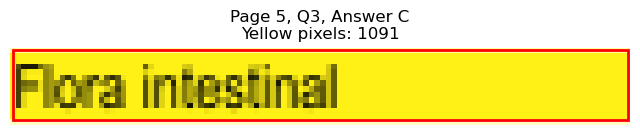

Page 5, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=358.1, y1=240.9
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 247
Page 5, Q3, D: Yellow percentage: 0.0%


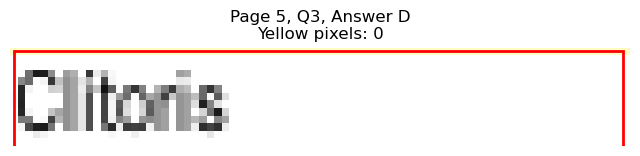


Page 5, Q3 - Selected Answer: C (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=179.1, y1=291.5
Page 5, Q4, A: Yellow pixels: 1697
Page 5, Q4, A: Total non-white pixels: 2268
Page 5, Q4, A: Yellow percentage: 74.8%


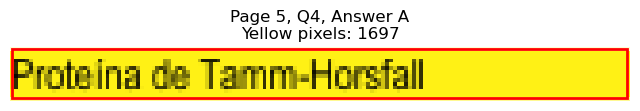

Page 5, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=125.5, y1=304.1
Page 5, Q4, B: Yellow pixels: 108
Page 5, Q4, B: Total non-white pixels: 388
Page 5, Q4, B: Yellow percentage: 27.8%


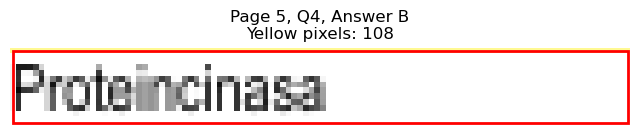

Page 5, Q4 - C: Detected box: x0=327.5, y0=278.8, x1=416.8, y1=291.5
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 430
Page 5, Q4, C: Yellow percentage: 0.0%


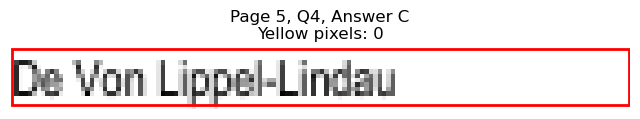

Page 5, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=376.7, y1=304.1
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 248
Page 5, Q4, D: Yellow percentage: 0.0%


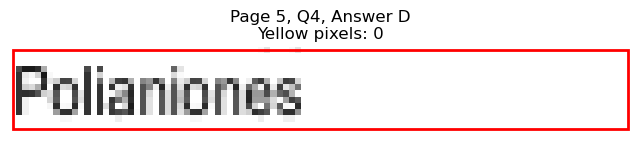


Page 5, Q4 - Selected Answer: A (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=329.2, x1=95.9, y1=341.9
Page 5, Q5, A: Yellow pixels: 944
Page 5, Q5, A: Total non-white pixels: 1014
Page 5, Q5, A: Yellow percentage: 93.1%


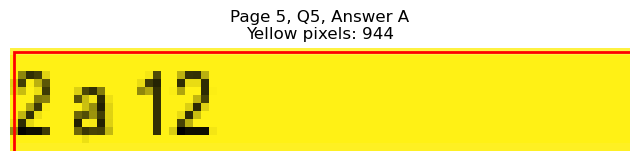

Page 5, Q5 - B: Detected box: x0=68.3, y0=341.9, x1=95.9, y1=354.6
Page 5, Q5, B: Yellow pixels: 78
Page 5, Q5, B: Total non-white pixels: 175
Page 5, Q5, B: Yellow percentage: 44.6%


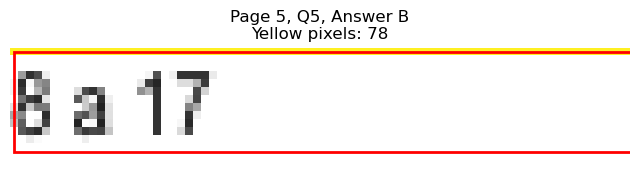

Page 5, Q5 - C: Detected box: x0=327.5, y0=329.2, x1=360.2, y1=341.9
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 147
Page 5, Q5, C: Yellow percentage: 0.0%


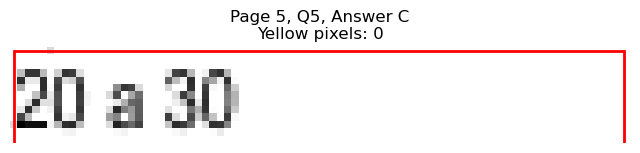

Page 5, Q5 - D: Detected box: x0=327.5, y0=341.9, x1=355.1, y1=354.6
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 109
Page 5, Q5, D: Yellow percentage: 0.0%


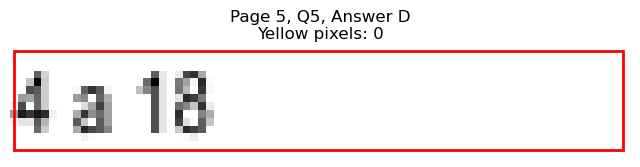


Page 5, Q5 - Selected Answer: A (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=379.7, x1=182.2, y1=392.4
Page 5, Q6, A: Yellow pixels: 1474
Page 5, Q6, A: Total non-white pixels: 2310
Page 5, Q6, A: Yellow percentage: 63.8%


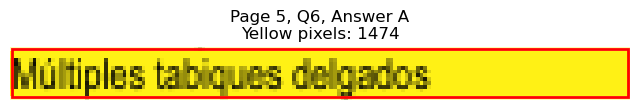

Page 5, Q6 - B: Detected box: x0=68.3, y0=392.3, x1=171.6, y1=405.0
Page 5, Q6, B: Yellow pixels: 0
Page 5, Q6, B: Total non-white pixels: 677
Page 5, Q6, B: Yellow percentage: 0.0%


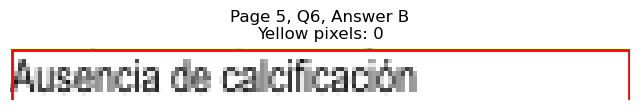

Page 5, Q6 - C: Detected box: x0=327.5, y0=379.7, x1=430.9, y1=392.4
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 547
Page 5, Q6, C: Yellow percentage: 0.0%


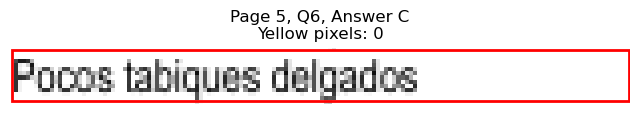

Page 5, Q6 - D: Detected box: x0=327.5, y0=392.3, x1=457.4, y1=405.0
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 646
Page 5, Q6, D: Yellow percentage: 0.0%


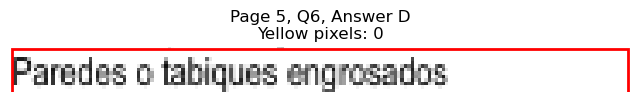


Page 5, Q6 - Selected Answer: A (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=430.2, x1=127.5, y1=442.9
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 346
Page 5, Q7, A: Yellow percentage: 0.0%


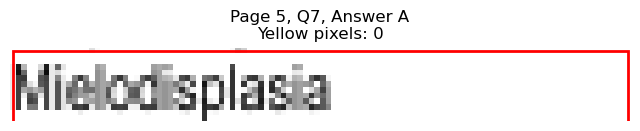

Page 5, Q7 - B: Detected box: x0=68.3, y0=442.8, x1=220.4, y1=455.5
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 734
Page 5, Q7, B: Yellow percentage: 0.0%


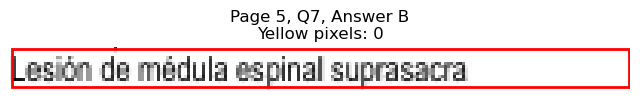

Page 5, Q7 - C: Detected box: x0=327.5, y0=430.2, x1=405.8, y1=442.9
Page 5, Q7, C: Yellow pixels: 1360
Page 5, Q7, C: Total non-white pixels: 1677
Page 5, Q7, C: Yellow percentage: 81.1%


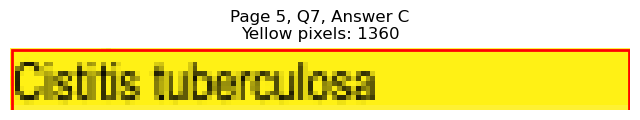

Page 5, Q7 - D: Detected box: x0=327.5, y0=442.8, x1=414.8, y1=455.5
Page 5, Q7, D: Yellow pixels: 138
Page 5, Q7, D: Total non-white pixels: 605
Page 5, Q7, D: Yellow percentage: 22.8%


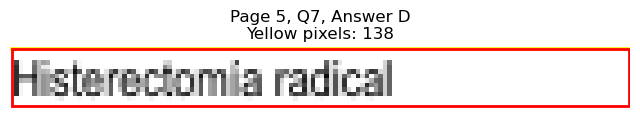


Page 5, Q7 - Selected Answer: C (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=480.8, x1=98.9, y1=493.4
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 103
Page 5, Q8, A: Yellow percentage: 0.0%


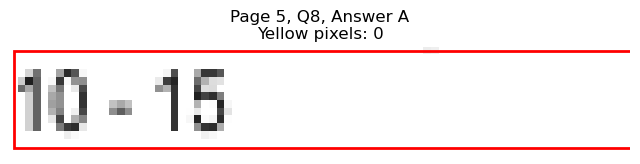

Page 5, Q8 - B: Detected box: x0=68.3, y0=493.4, x1=93.9, y1=506.0
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 82
Page 5, Q8, B: Yellow percentage: 0.0%


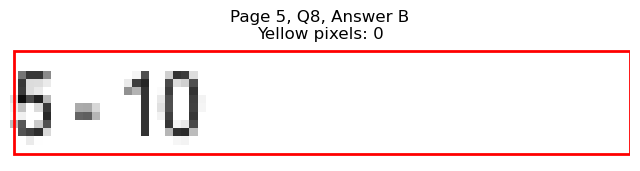

Page 5, Q8 - C: Detected box: x0=327.5, y0=480.8, x1=358.1, y1=493.4
Page 5, Q8, C: Yellow pixels: 82
Page 5, Q8, C: Total non-white pixels: 214
Page 5, Q8, C: Yellow percentage: 38.3%


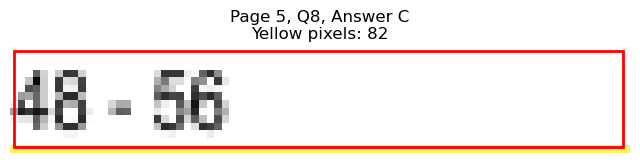

Page 5, Q8 - D: Detected box: x0=327.5, y0=493.4, x1=358.1, y1=506.0
Page 5, Q8, D: Yellow pixels: 973
Page 5, Q8, D: Total non-white pixels: 1066
Page 5, Q8, D: Yellow percentage: 91.3%


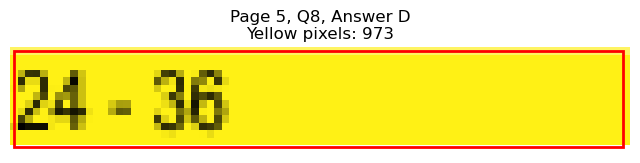


Page 5, Q8 - Selected Answer: D (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=531.2, x1=107.4, y1=543.8
Page 5, Q9, A: Yellow pixels: 1015
Page 5, Q9, A: Total non-white pixels: 1170
Page 5, Q9, A: Yellow percentage: 86.8%


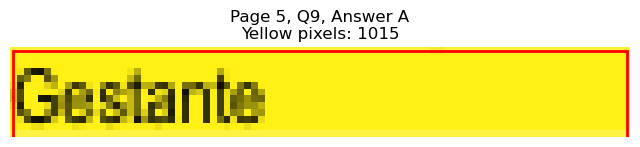

Page 5, Q9 - B: Detected box: x0=68.3, y0=543.8, x1=108.4, y1=556.4
Page 5, Q9, B: Yellow pixels: 91
Page 5, Q9, B: Total non-white pixels: 309
Page 5, Q9, B: Yellow percentage: 29.4%


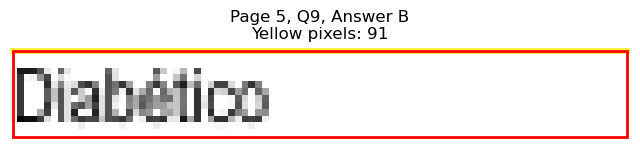

Page 5, Q9 - C: Detected box: x0=327.5, y0=531.2, x1=404.3, y1=543.8
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 377
Page 5, Q9, C: Yellow percentage: 0.0%


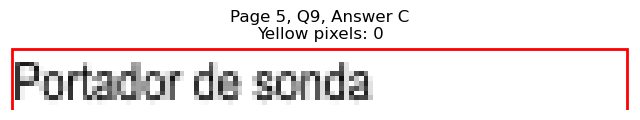

Page 5, Q9 - D: Detected box: x0=327.5, y0=543.8, x1=392.8, y1=556.4
Page 5, Q9, D: Yellow pixels: 0
Page 5, Q9, D: Total non-white pixels: 314
Page 5, Q9, D: Yellow percentage: 0.0%


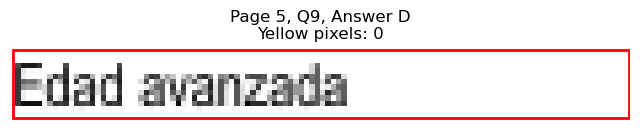


Page 5, Q9 - Selected Answer: A (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=68.3, y0=581.7, x1=168.1, y1=594.4
Page 5, Q10, A: Yellow pixels: 1419
Page 5, Q10, A: Total non-white pixels: 2114
Page 5, Q10, A: Yellow percentage: 67.1%


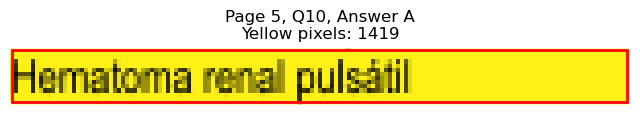

Page 5, Q10 - B: Detected box: x0=68.3, y0=594.3, x1=162.6, y1=607.0
Page 5, Q10, B: Yellow pixels: 0
Page 5, Q10, B: Total non-white pixels: 616
Page 5, Q10, B: Yellow percentage: 0.0%


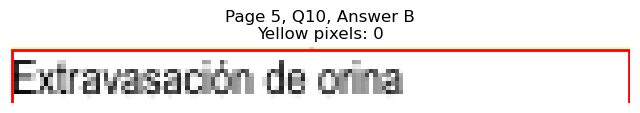

Page 5, Q10 - C: Detected box: x0=327.5, y0=581.7, x1=431.8, y1=594.4
Page 5, Q10, C: Yellow pixels: 0
Page 5, Q10, C: Total non-white pixels: 527
Page 5, Q10, C: Yellow percentage: 0.0%


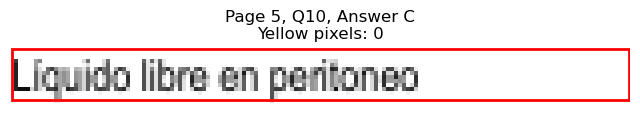

Page 5, Q10 - D: Detected box: x0=327.5, y0=594.3, x1=487.1, y1=607.0
Page 5, Q10, D: Yellow pixels: 0
Page 5, Q10, D: Total non-white pixels: 790
Page 5, Q10, D: Yellow percentage: 0.0%


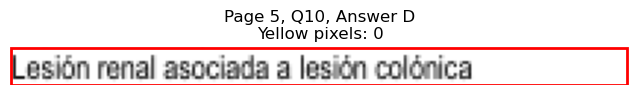


Page 5, Q10 - Selected Answer: A (based on yellow pixel count)




Page 5, Q11 - A: Detected box: x0=68.3, y0=632.2, x1=145.0, y1=644.9
Page 5, Q11, A: Yellow pixels: 0
Page 5, Q11, A: Total non-white pixels: 382
Page 5, Q11, A: Yellow percentage: 0.0%


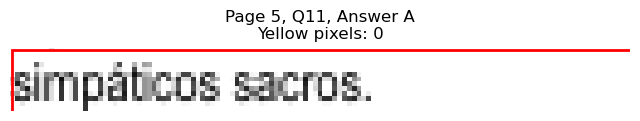

Page 5, Q11 - B: Detected box: x0=68.3, y0=644.9, x1=173.7, y1=657.5
Page 5, Q11, B: Yellow pixels: 0
Page 5, Q11, B: Total non-white pixels: 534
Page 5, Q11, B: Yellow percentage: 0.0%


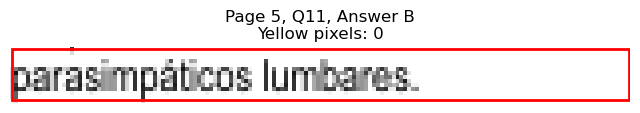

Page 5, Q11 - C: Detected box: x0=327.5, y0=632.2, x1=422.3, y1=644.9
Page 5, Q11, C: Yellow pixels: 1535
Page 5, Q11, C: Total non-white pixels: 1898
Page 5, Q11, C: Yellow percentage: 80.9%


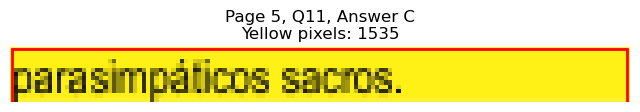

Page 5, Q11 - D: Detected box: x0=327.5, y0=644.9, x1=434.3, y1=657.5
Page 5, Q11, D: Yellow pixels: 0
Page 5, Q11, D: Total non-white pixels: 560
Page 5, Q11, D: Yellow percentage: 0.0%


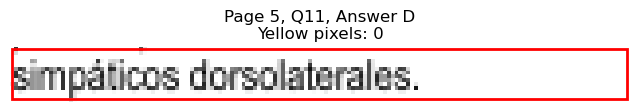


Page 5, Q11 - Selected Answer: C (based on yellow pixel count)




Page 5, Q12 - A: Detected box: x0=68.3, y0=682.7, x1=115.0, y1=695.3
Page 5, Q12, A: Yellow pixels: 991
Page 5, Q12, A: Total non-white pixels: 1358
Page 5, Q12, A: Yellow percentage: 73.0%


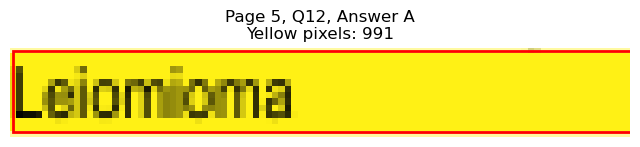

Page 5, Q12 - B: Detected box: x0=68.3, y0=695.4, x1=108.4, y1=708.0
Page 5, Q12, B: Yellow pixels: 0
Page 5, Q12, B: Total non-white pixels: 299
Page 5, Q12, B: Yellow percentage: 0.0%


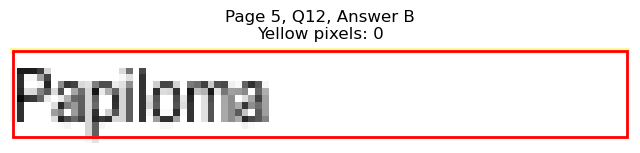

Page 5, Q12 - C: Detected box: x0=327.5, y0=682.7, x1=378.2, y1=695.3
Page 5, Q12, C: Yellow pixels: 0
Page 5, Q12, C: Total non-white pixels: 249
Page 5, Q12, C: Yellow percentage: 0.0%


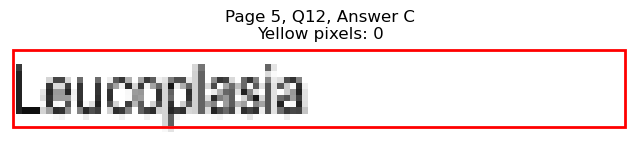

Page 5, Q12 - D: Detected box: x0=327.5, y0=695.4, x1=395.7, y1=708.0
Page 5, Q12, D: Yellow pixels: 0
Page 5, Q12, D: Total non-white pixels: 365
Page 5, Q12, D: Yellow percentage: 0.0%


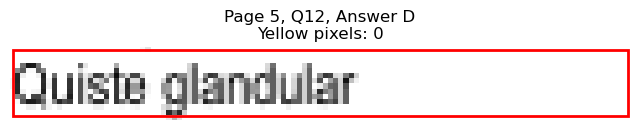


Page 5, Q12 - Selected Answer: A (based on yellow pixel count)




Page 5, Q13 - A: Detected box: x0=68.3, y0=745.8, x1=204.2, y1=758.4
Page 5, Q13, A: Yellow pixels: 0
Page 5, Q13, A: Total non-white pixels: 672
Page 5, Q13, A: Yellow percentage: 0.0%


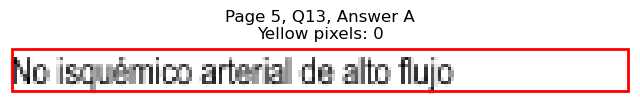

Page 5, Q13 - B: Detected box: x0=68.3, y0=758.5, x1=228.8, y1=771.2
Page 5, Q13, B: Yellow pixels: 0
Page 5, Q13, B: Total non-white pixels: 791
Page 5, Q13, B: Yellow percentage: 0.0%


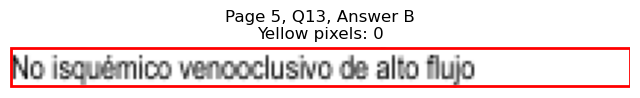

Page 5, Q13 - C: Detected box: x0=327.5, y0=745.8, x1=477.0, y1=758.4
Page 5, Q13, C: Yellow pixels: 2041
Page 5, Q13, C: Total non-white pixels: 2800
Page 5, Q13, C: Yellow percentage: 72.9%


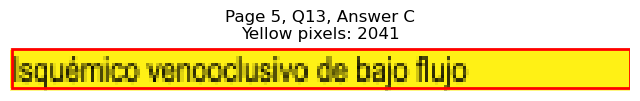

Page 5, Q13 - D: Detected box: x0=327.5, y0=758.5, x1=452.5, y1=771.2
Page 5, Q13, D: Yellow pixels: 174
Page 5, Q13, D: Total non-white pixels: 825
Page 5, Q13, D: Yellow percentage: 21.1%


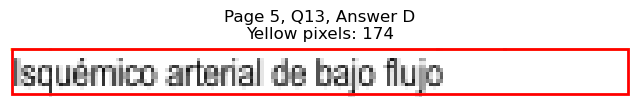


Page 5, Q13 - Selected Answer: C (based on yellow pixel count)





Page 6: Found 12 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=129.5, y1=127.3
Page 6, Q1, A: Yellow pixels: 1079
Page 6, Q1, A: Total non-white pixels: 1568
Page 6, Q1, A: Yellow percentage: 68.8%


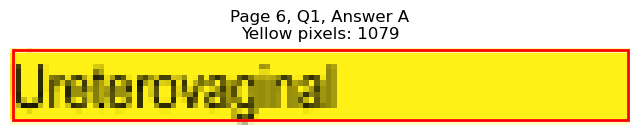

Page 6, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=126.5, y1=139.9
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 426
Page 6, Q1, B: Yellow percentage: 0.0%


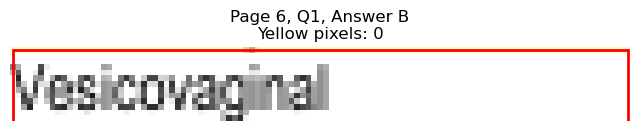

Page 6, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=383.7, y1=127.3
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 305
Page 6, Q1, C: Yellow percentage: 0.0%


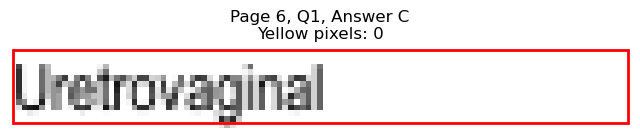

Page 6, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=389.2, y1=139.9
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 335
Page 6, Q1, D: Yellow percentage: 0.0%


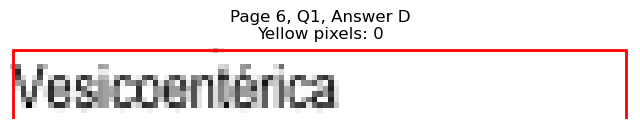


Page 6, Q1 - Selected Answer: A (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=187.7, y1=177.8
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 782
Page 6, Q2, A: Yellow percentage: 0.0%


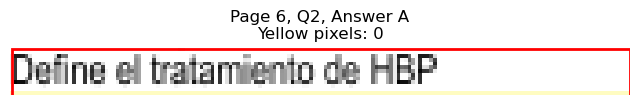

Page 6, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=305.1, y1=190.4
Page 6, Q2, B: Yellow pixels: 2581
Page 6, Q2, B: Total non-white pixels: 4032
Page 6, Q2, B: Yellow percentage: 64.0%


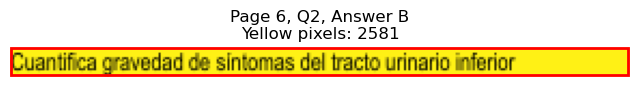

Page 6, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=192.6, y1=203.0
Page 6, Q2, C: Yellow pixels: 1
Page 6, Q2, C: Total non-white pixels: 842
Page 6, Q2, C: Yellow percentage: 0.1%


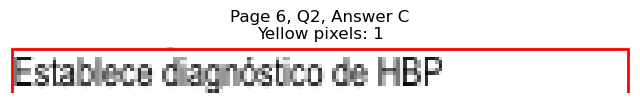

Page 6, Q2 - D: Detected box: x0=68.8, y0=202.9, x1=176.1, y1=215.6
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 553
Page 6, Q2, D: Yellow percentage: 0.0%


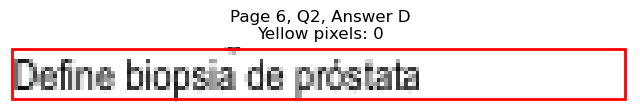


Page 6, Q2 - Selected Answer: B (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=112.0, y1=266.1
Page 6, Q3, A: Yellow pixels: 1056
Page 6, Q3, A: Total non-white pixels: 1316
Page 6, Q3, A: Yellow percentage: 80.2%


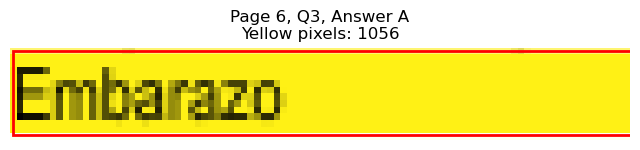

Page 6, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=109.9, y1=278.7
Page 6, Q3, B: Yellow pixels: 0
Page 6, Q3, B: Total non-white pixels: 314
Page 6, Q3, B: Yellow percentage: 0.0%


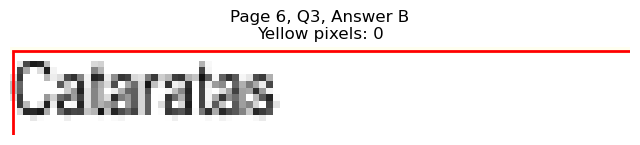

Page 6, Q3 - C: Detected box: x0=327.5, y0=253.5, x1=371.7, y1=266.1
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 226
Page 6, Q3, C: Yellow percentage: 0.0%


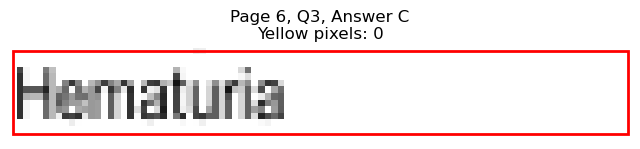

Page 6, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=410.8, y1=278.7
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 453
Page 6, Q3, D: Yellow percentage: 0.0%


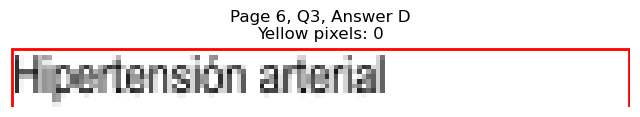


Page 6, Q3 - Selected Answer: A (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=121.0, y1=316.7
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 240
Page 6, Q4, A: Yellow percentage: 0.0%


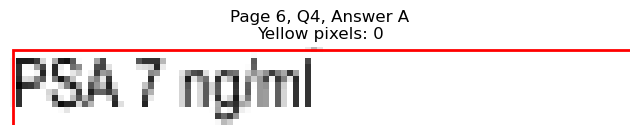

Page 6, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=108.1, y1=329.3
Page 6, Q4, B: Yellow pixels: 0
Page 6, Q4, B: Total non-white pixels: 188
Page 6, Q4, B: Yellow percentage: 0.0%


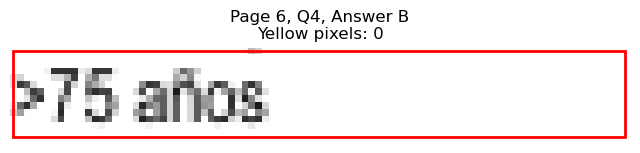

Page 6, Q4 - C: Detected box: x0=327.5, y0=253.5, x1=371.7, y1=266.1
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 226
Page 6, Q4, C: Yellow percentage: 0.0%


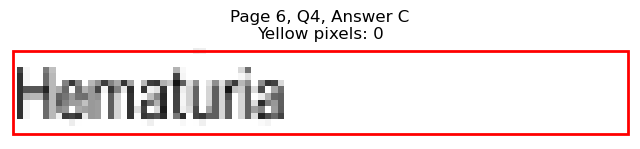

Page 6, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=528.0, y1=329.3
Page 6, Q4, D: Yellow pixels: 1838
Page 6, Q4, D: Total non-white pixels: 2996
Page 6, Q4, D: Yellow percentage: 61.3%


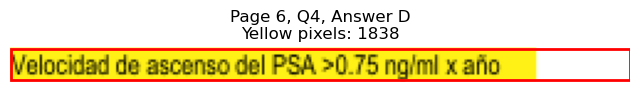


Page 6, Q4 - Selected Answer: D (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=354.5, x1=148.0, y1=367.2
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 375
Page 6, Q5, A: Yellow percentage: 0.0%


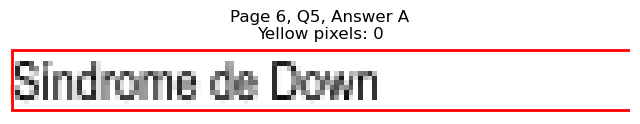

Page 6, Q5 - B: Detected box: x0=68.3, y0=367.1, x1=138.0, y1=379.8
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 327
Page 6, Q5, B: Yellow percentage: 0.0%


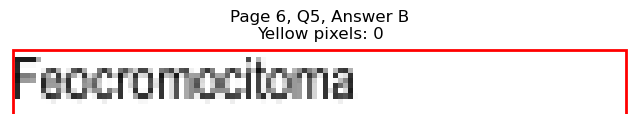

Page 6, Q5 - C: Detected box: x0=327.5, y0=354.5, x1=352.6, y1=367.2
Page 6, Q5, C: Yellow pixels: 76
Page 6, Q5, C: Total non-white pixels: 213
Page 6, Q5, C: Yellow percentage: 35.7%


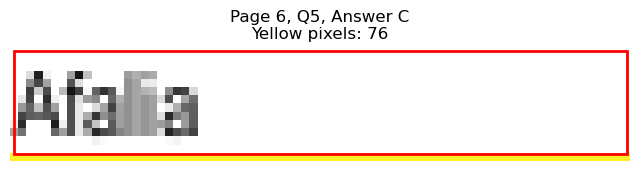

Page 6, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=469.5, y1=379.8
Page 6, Q5, D: Yellow pixels: 1917
Page 6, Q5, D: Total non-white pixels: 2509
Page 6, Q5, D: Yellow percentage: 76.4%


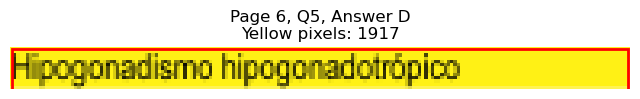


Page 6, Q5 - Selected Answer: D (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=404.9, x1=183.1, y1=417.6
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 546
Page 6, Q6, A: Yellow percentage: 0.0%


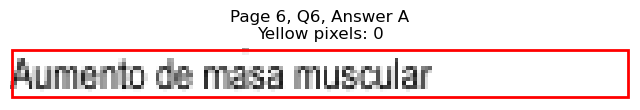

Page 6, Q6 - B: Detected box: x0=68.3, y0=417.6, x1=211.7, y1=430.3
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 685
Page 6, Q6, B: Yellow percentage: 0.0%


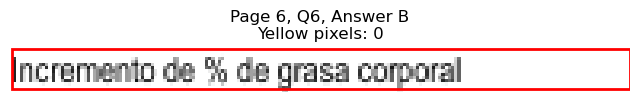

Page 6, Q6 - C: Detected box: x0=327.5, y0=253.5, x1=371.7, y1=266.1
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 226
Page 6, Q6, C: Yellow percentage: 0.0%


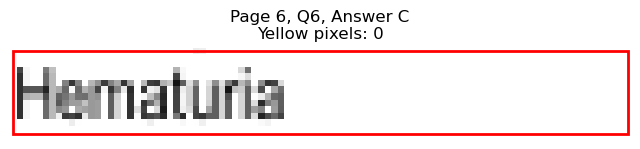

Page 6, Q6 - D: Detected box: x0=327.5, y0=417.6, x1=383.2, y1=430.3
Page 6, Q6, D: Yellow pixels: 1071
Page 6, Q6, D: Total non-white pixels: 1498
Page 6, Q6, D: Yellow percentage: 71.5%


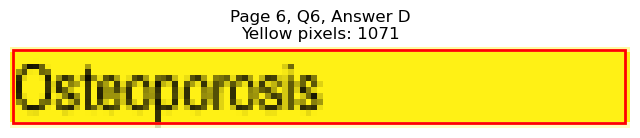


Page 6, Q6 - Selected Answer: D (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=468.1, x1=177.6, y1=480.7
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 537
Page 6, Q7, A: Yellow percentage: 0.0%


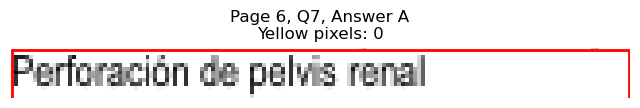

Page 6, Q7 - B: Detected box: x0=68.3, y0=480.8, x1=152.5, y1=493.4
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 418
Page 6, Q7, B: Yellow percentage: 0.0%


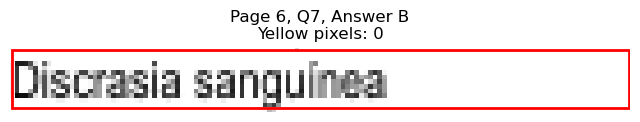

Page 6, Q7 - C: Detected box: x0=327.5, y0=468.1, x1=398.8, y1=480.7
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 367
Page 6, Q7, C: Yellow percentage: 0.0%


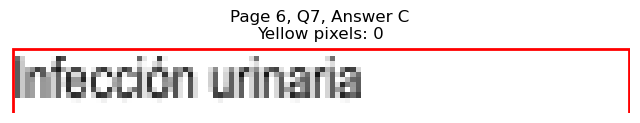

Page 6, Q7 - D: Detected box: x0=327.5, y0=480.8, x1=428.3, y1=493.4
Page 6, Q7, D: Yellow pixels: 1443
Page 6, Q7, D: Total non-white pixels: 2128
Page 6, Q7, D: Yellow percentage: 67.8%


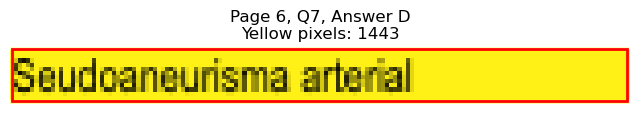


Page 6, Q7 - Selected Answer: D (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=518.6, x1=124.0, y1=531.2
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 300
Page 6, Q8, A: Yellow percentage: 0.0%


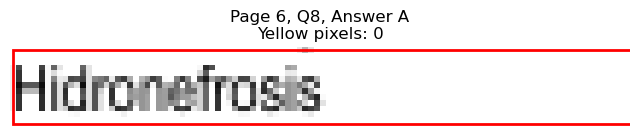

Page 6, Q8 - B: Detected box: x0=68.3, y0=531.2, x1=127.9, y1=543.8
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 280
Page 6, Q8, B: Yellow percentage: 0.0%


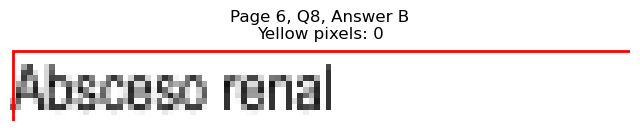

Page 6, Q8 - C: Detected box: x0=327.5, y0=518.6, x1=378.7, y1=531.2
Page 6, Q8, C: Yellow pixels: 1135
Page 6, Q8, C: Total non-white pixels: 1428
Page 6, Q8, C: Yellow percentage: 79.5%


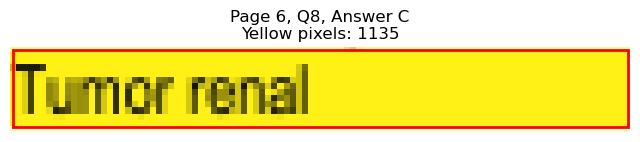

Page 6, Q8 - D: Detected box: x0=327.5, y0=531.2, x1=404.8, y1=543.8
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 534
Page 6, Q8, D: Yellow percentage: 0.0%


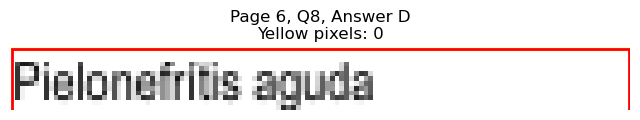


Page 6, Q8 - Selected Answer: C (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=569.1, x1=165.1, y1=581.8
Page 6, Q9, A: Yellow pixels: 1531
Page 6, Q9, A: Total non-white pixels: 1924
Page 6, Q9, A: Yellow percentage: 79.6%


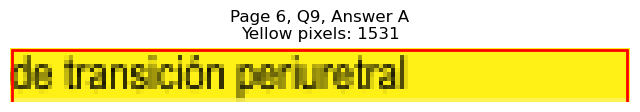

Page 6, Q9 - B: Detected box: x0=68.3, y0=581.7, x1=97.9, y1=594.4
Page 6, Q9, B: Yellow pixels: 80
Page 6, Q9, B: Total non-white pixels: 217
Page 6, Q9, B: Yellow percentage: 36.9%


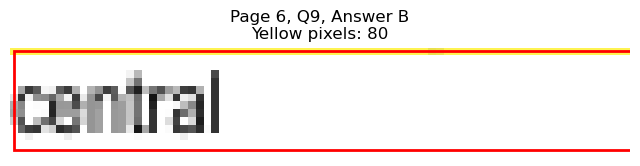

Page 6, Q9 - C: Detected box: x0=327.5, y0=569.1, x1=367.1, y1=581.8
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 202
Page 6, Q9, C: Yellow percentage: 0.0%


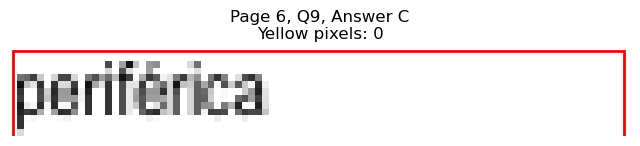

Page 6, Q9 - D: Detected box: x0=327.5, y0=581.7, x1=402.8, y1=594.4
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 407
Page 6, Q9, D: Yellow percentage: 0.0%


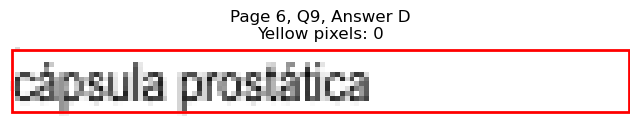


Page 6, Q9 - Selected Answer: A (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=68.3, y0=644.9, x1=178.1, y1=657.5
Page 6, Q10, A: Yellow pixels: 0
Page 6, Q10, A: Total non-white pixels: 563
Page 6, Q10, A: Yellow percentage: 0.0%


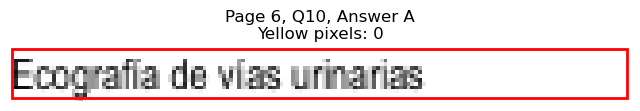

Page 6, Q10 - B: Detected box: x0=68.3, y0=657.5, x1=191.7, y1=670.1
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 648
Page 6, Q10, B: Yellow percentage: 0.0%


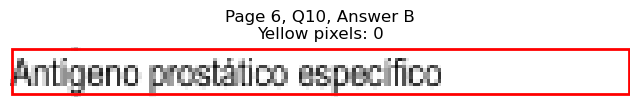

Page 6, Q10 - C: Detected box: x0=327.5, y0=644.9, x1=370.1, y1=657.5
Page 6, Q10, C: Yellow pixels: 1061
Page 6, Q10, C: Total non-white pixels: 1316
Page 6, Q10, C: Yellow percentage: 80.6%


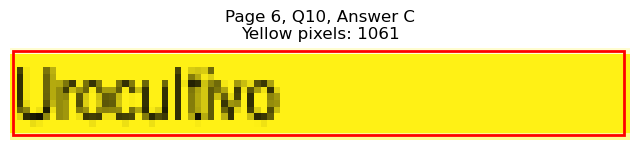

Page 6, Q10 - D: Detected box: x0=327.5, y0=657.5, x1=371.2, y1=670.1
Page 6, Q10, D: Yellow pixels: 95
Page 6, Q10, D: Total non-white pixels: 309
Page 6, Q10, D: Yellow percentage: 30.7%


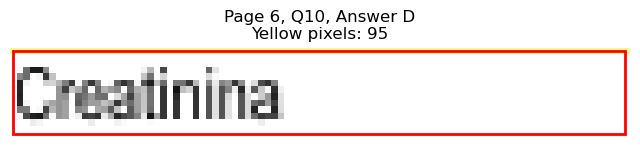


Page 6, Q10 - Selected Answer: C (based on yellow pixel count)




Page 6, Q11 - A: Detected box: x0=68.3, y0=695.4, x1=220.7, y1=708.0
Page 6, Q11, A: Yellow pixels: 2048
Page 6, Q11, A: Total non-white pixels: 2646
Page 6, Q11, A: Yellow percentage: 77.4%


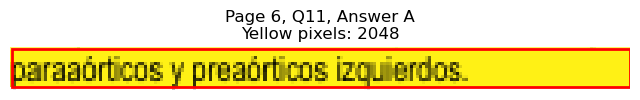

Page 6, Q11 - B: Detected box: x0=68.3, y0=708.0, x1=161.1, y1=720.6
Page 6, Q11, B: Yellow pixels: 137
Page 6, Q11, B: Total non-white pixels: 588
Page 6, Q11, B: Yellow percentage: 23.3%


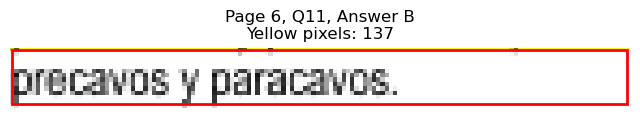

Page 6, Q11 - C: Detected box: x0=327.5, y0=695.4, x1=433.4, y1=708.0
Page 6, Q11, C: Yellow pixels: 0
Page 6, Q11, C: Total non-white pixels: 509
Page 6, Q11, C: Yellow percentage: 0.0%


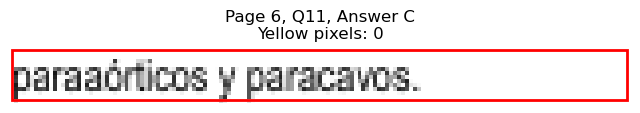

Page 6, Q11 - D: Detected box: x0=327.5, y0=708.0, x1=447.4, y1=720.6
Page 6, Q11, D: Yellow pixels: 0
Page 6, Q11, D: Total non-white pixels: 575
Page 6, Q11, D: Yellow percentage: 0.0%


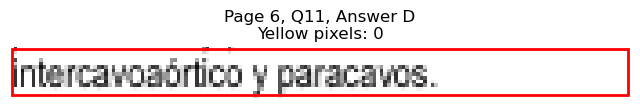


Page 6, Q11 - Selected Answer: A (based on yellow pixel count)




Page 6, Q12 - A: Detected box: x0=68.3, y0=745.8, x1=133.0, y1=758.4
Page 6, Q12, A: Yellow pixels: 0
Page 6, Q12, A: Total non-white pixels: 319
Page 6, Q12, A: Yellow percentage: 0.0%


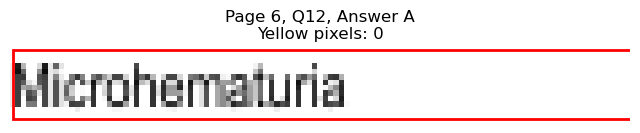

Page 6, Q12 - B: Detected box: x0=68.3, y0=758.5, x1=129.0, y1=771.2
Page 6, Q12, B: Yellow pixels: 1229
Page 6, Q12, B: Total non-white pixels: 1568
Page 6, Q12, B: Yellow percentage: 78.4%


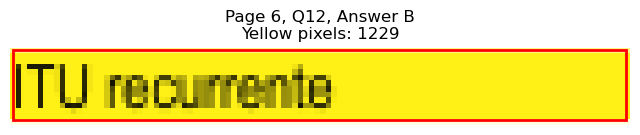

Page 6, Q12 - C: Detected box: x0=327.5, y0=745.8, x1=448.6, y1=758.4
Page 6, Q12, C: Yellow pixels: 0
Page 6, Q12, C: Total non-white pixels: 606
Page 6, Q12, C: Yellow percentage: 0.0%


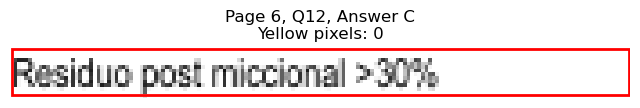

Page 6, Q12 - D: Detected box: x0=327.5, y0=758.5, x1=412.0, y1=771.2
Page 6, Q12, D: Yellow pixels: 0
Page 6, Q12, D: Total non-white pixels: 402
Page 6, Q12, D: Yellow percentage: 0.0%


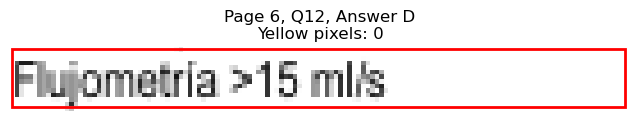


Page 6, Q12 - Selected Answer: B (based on yellow pixel count)





Page 7: Found 10 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=121.9, y1=102.1
Page 7, Q1, A: Yellow pixels: 104
Page 7, Q1, A: Total non-white pixels: 360
Page 7, Q1, A: Yellow percentage: 28.9%


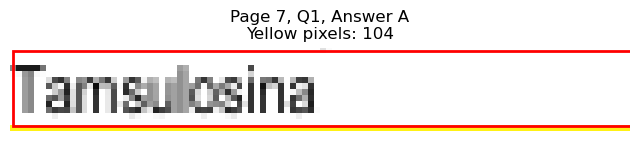

Page 7, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=112.5, y1=114.7
Page 7, Q1, B: Yellow pixels: 1046
Page 7, Q1, B: Total non-white pixels: 1235
Page 7, Q1, B: Yellow percentage: 84.7%


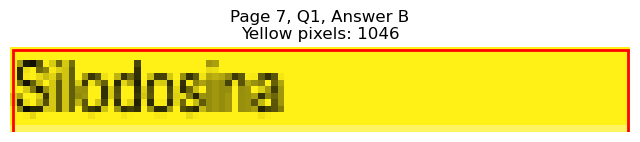

Page 7, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=375.7, y1=102.1
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 267
Page 7, Q1, C: Yellow percentage: 0.0%


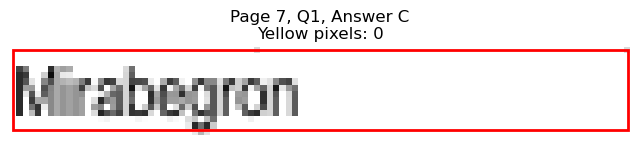

Page 7, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=379.3, y1=114.7
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 273
Page 7, Q1, D: Yellow percentage: 0.0%


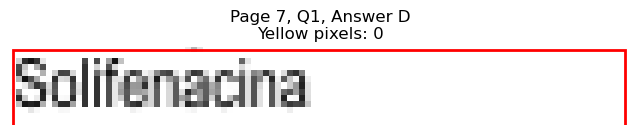


Page 7, Q1 - Selected Answer: B (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=154.1, y1=177.8
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 440
Page 7, Q2, A: Yellow percentage: 0.0%


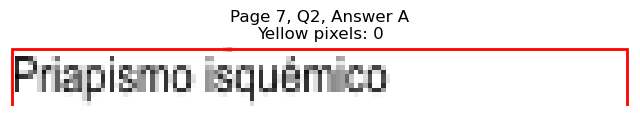

Page 7, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=160.6, y1=190.4
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 481
Page 7, Q2, B: Yellow percentage: 0.0%


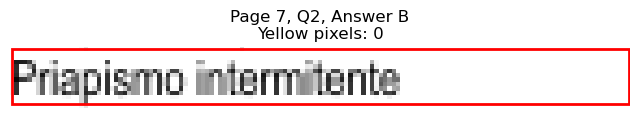

Page 7, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=425.8, y1=177.8
Page 7, Q2, C: Yellow pixels: 1573
Page 7, Q2, C: Total non-white pixels: 1937
Page 7, Q2, C: Yellow percentage: 81.2%


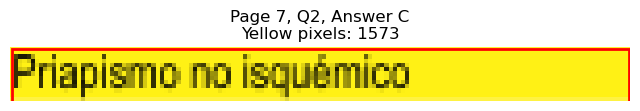

Page 7, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=412.7, y1=190.4
Page 7, Q2, D: Yellow pixels: 136
Page 7, Q2, D: Total non-white pixels: 568
Page 7, Q2, D: Yellow percentage: 23.9%


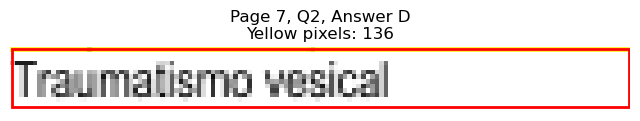


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=201.2, y1=228.3
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 670
Page 7, Q3, A: Yellow percentage: 0.0%


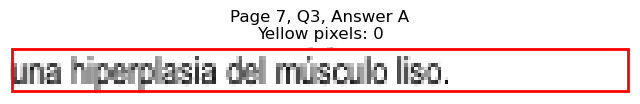

Page 7, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=260.0, y1=240.9
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 934
Page 7, Q3, B: Yellow percentage: 0.0%


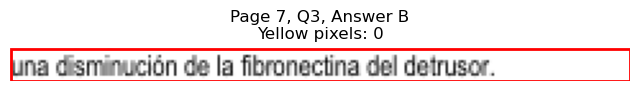

Page 7, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=472.5, y1=228.3
Page 7, Q3, C: Yellow pixels: 196
Page 7, Q3, C: Total non-white pixels: 853
Page 7, Q3, C: Yellow percentage: 23.0%


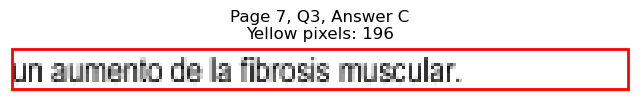

Page 7, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=484.1, y1=240.9
Page 7, Q3, D: Yellow pixels: 2142
Page 7, Q3, D: Total non-white pixels: 2704
Page 7, Q3, D: Yellow percentage: 79.2%


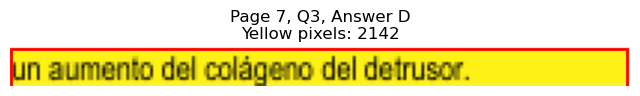


Page 7, Q3 - Selected Answer: D (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=56.6, y0=291.4, x1=65.2, y1=304.1
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 62
Page 7, Q4, A: Yellow percentage: 0.0%


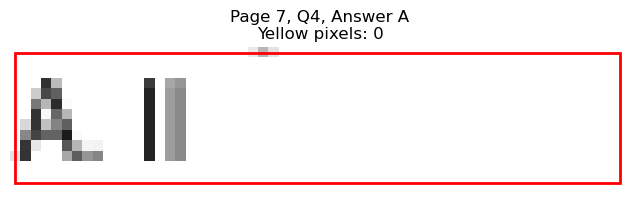

Page 7, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=79.3, y1=316.7
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 36
Page 7, Q4, B: Yellow percentage: 0.0%


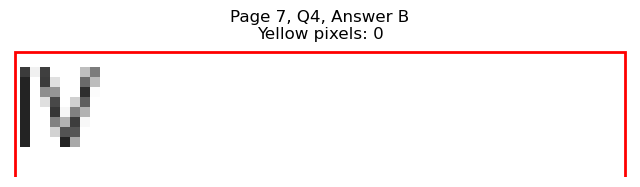

Page 7, Q4 - C: Detected box: x0=327.5, y0=291.4, x1=337.6, y1=304.1
Page 7, Q4, C: Yellow pixels: 753
Page 7, Q4, C: Total non-white pixels: 854
Page 7, Q4, C: Yellow percentage: 88.2%


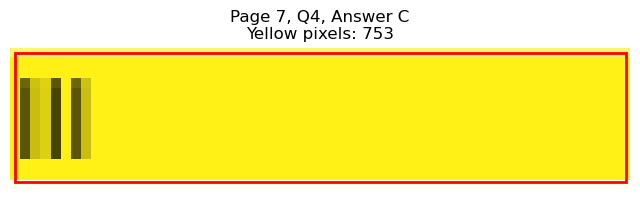

Page 7, Q4 - D: Detected box: x0=315.4, y0=304.0, x1=324.4, y1=316.7
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 116
Page 7, Q4, D: Yellow percentage: 0.0%


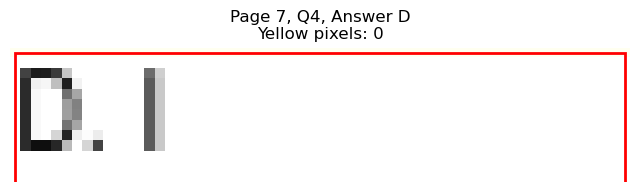


Page 7, Q4 - Selected Answer: C (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=164.5, y1=379.8
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 625
Page 7, Q5, A: Yellow percentage: 0.0%


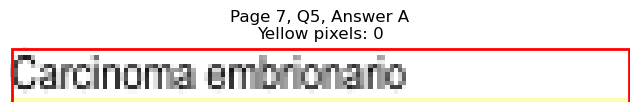

Page 7, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=113.9, y1=392.4
Page 7, Q5, B: Yellow pixels: 973
Page 7, Q5, B: Total non-white pixels: 1344
Page 7, Q5, B: Yellow percentage: 72.4%


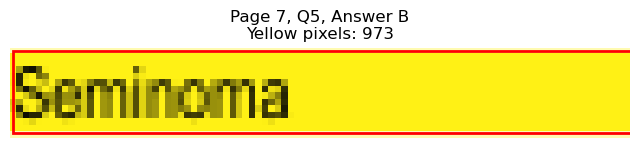

Page 7, Q5 - C: Detected box: x0=327.5, y0=367.1, x1=396.3, y1=379.8
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 351
Page 7, Q5, C: Yellow percentage: 0.0%


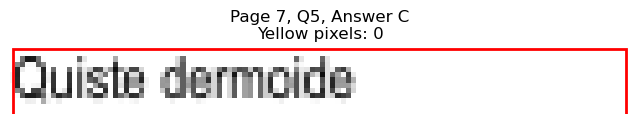

Page 7, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=362.1, y1=392.4
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 146
Page 7, Q5, D: Yellow percentage: 0.0%


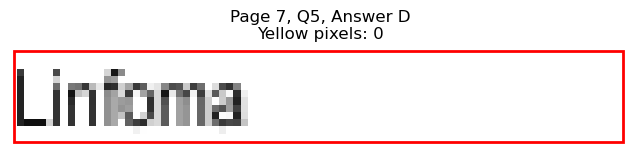


Page 7, Q5 - Selected Answer: B (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=430.2, x1=135.0, y1=442.9
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 425
Page 7, Q6, A: Yellow percentage: 0.0%


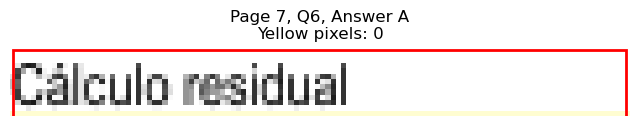

Page 7, Q6 - B: Detected box: x0=68.3, y0=442.8, x1=155.1, y1=455.5
Page 7, Q6, B: Yellow pixels: 1457
Page 7, Q6, B: Total non-white pixels: 1932
Page 7, Q6, B: Yellow percentage: 75.4%


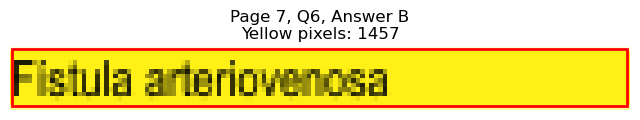

Page 7, Q6 - C: Detected box: x0=327.5, y0=430.2, x1=398.8, y1=442.9
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 367
Page 7, Q6, C: Yellow percentage: 0.0%


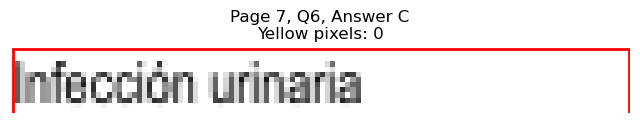

Page 7, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=413.8, y1=455.5
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 400
Page 7, Q6, D: Yellow percentage: 0.0%


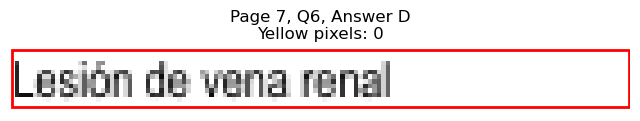


Page 7, Q6 - Selected Answer: B (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=506.0, x1=185.2, y1=518.6
Page 7, Q7, A: Yellow pixels: 168
Page 7, Q7, A: Total non-white pixels: 784
Page 7, Q7, A: Yellow percentage: 21.4%


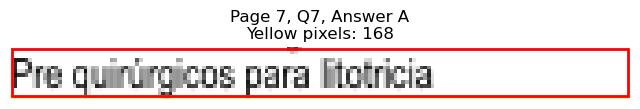

Page 7, Q7 - B: Detected box: x0=68.3, y0=518.6, x1=183.4, y1=531.2
Page 7, Q7, B: Yellow pixels: 1718
Page 7, Q7, B: Total non-white pixels: 2324
Page 7, Q7, B: Yellow percentage: 73.9%


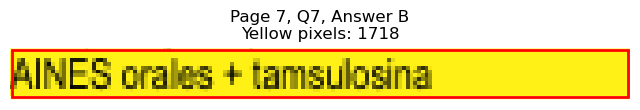

Page 7, Q7 - C: Detected box: x0=327.5, y0=506.0, x1=471.8, y1=518.6
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 719
Page 7, Q7, C: Yellow percentage: 0.0%


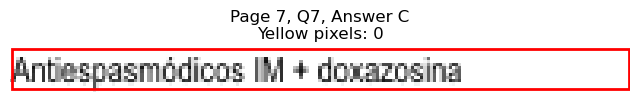

Page 7, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=474.8, y1=531.2
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 742
Page 7, Q7, D: Yellow percentage: 0.0%


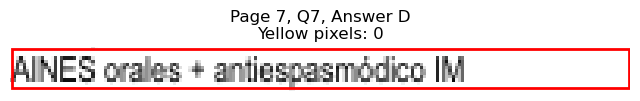


Page 7, Q7 - Selected Answer: B (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=556.5, x1=102.4, y1=569.2
Page 7, Q8, A: Yellow pixels: 978
Page 7, Q8, A: Total non-white pixels: 1190
Page 7, Q8, A: Yellow percentage: 82.2%


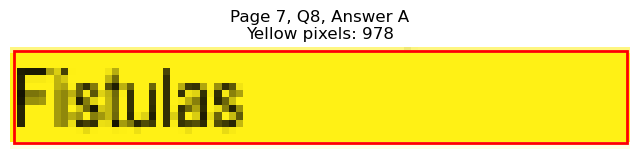

Page 7, Q8 - B: Detected box: x0=68.3, y0=569.1, x1=181.1, y1=581.8
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 730
Page 7, Q8, B: Yellow percentage: 0.0%


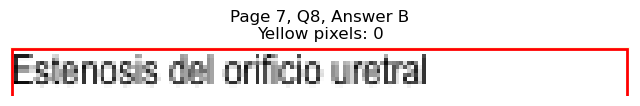

Page 7, Q8 - C: Detected box: x0=327.5, y0=556.5, x1=379.1, y1=569.2
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 278
Page 7, Q8, C: Yellow percentage: 0.0%


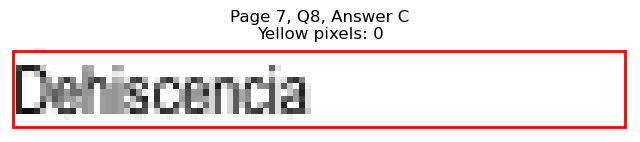

Page 7, Q8 - D: Detected box: x0=327.5, y0=569.1, x1=400.7, y1=581.8
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 375
Page 7, Q8, D: Yellow percentage: 0.0%


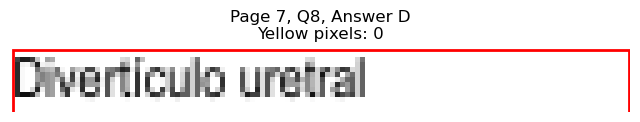


Page 7, Q8 - Selected Answer: A (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=632.2, x1=208.7, y1=644.9
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 882
Page 7, Q9, A: Yellow percentage: 0.0%


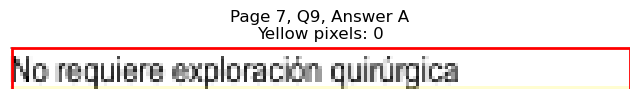

Page 7, Q9 - B: Detected box: x0=68.3, y0=644.9, x1=149.1, y1=657.5
Page 7, Q9, B: Yellow pixels: 1387
Page 7, Q9, B: Total non-white pixels: 1848
Page 7, Q9, B: Yellow percentage: 75.1%


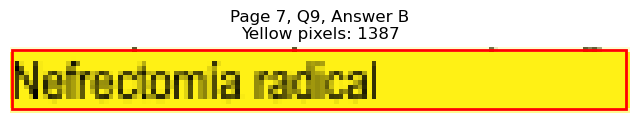

Page 7, Q9 - C: Detected box: x0=327.5, y0=632.2, x1=466.0, y1=644.9
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 667
Page 7, Q9, C: Yellow percentage: 0.0%


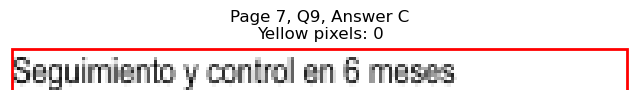

Page 7, Q9 - D: Detected box: x0=327.5, y0=644.9, x1=452.9, y1=657.5
Page 7, Q9, D: Yellow pixels: 0
Page 7, Q9, D: Total non-white pixels: 659
Page 7, Q9, D: Yellow percentage: 0.0%


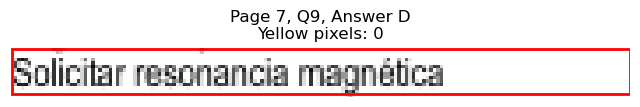


Page 7, Q9 - Selected Answer: B (based on yellow pixel count)




Page 7, Q10 - A: Detected box: x0=68.3, y0=695.4, x1=113.4, y1=708.0
Page 7, Q10, A: Yellow pixels: 0
Page 7, Q10, A: Total non-white pixels: 243
Page 7, Q10, A: Yellow percentage: 0.0%


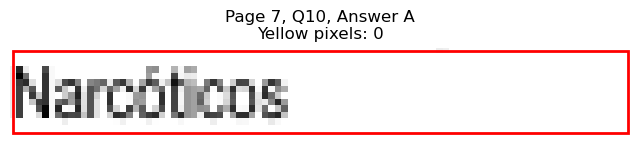

Page 7, Q10 - B: Detected box: x0=68.3, y0=708.0, x1=115.9, y1=720.6
Page 7, Q10, B: Yellow pixels: 0
Page 7, Q10, B: Total non-white pixels: 253
Page 7, Q10, B: Yellow percentage: 0.0%


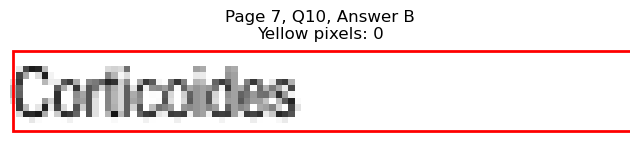

Page 7, Q10 - C: Detected box: x0=327.5, y0=695.4, x1=398.8, y1=708.0
Page 7, Q10, C: Yellow pixels: 122
Page 7, Q10, C: Total non-white pixels: 622
Page 7, Q10, C: Yellow percentage: 19.6%


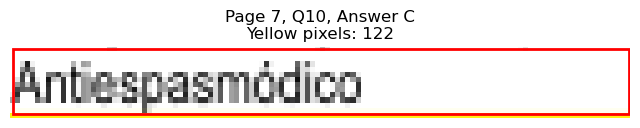

Page 7, Q10 - D: Detected box: x0=327.5, y0=518.6, x1=357.0, y1=531.2
Page 7, Q10, D: Yellow pixels: 0
Page 7, Q10, D: Total non-white pixels: 398
Page 7, Q10, D: Yellow percentage: 0.0%


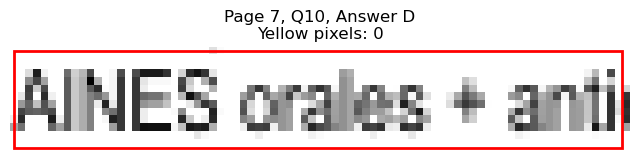


Page 7, Q10 - Selected Answer: C (based on yellow pixel count)





Page 8: Found 11 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=116.4, y1=114.7
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 224
Page 8, Q1, A: Yellow percentage: 0.0%


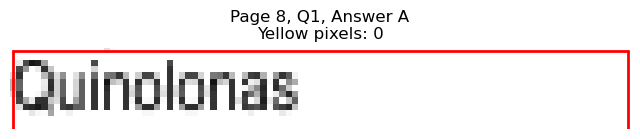

Page 8, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=130.9, y1=127.3
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 344
Page 8, Q1, B: Yellow percentage: 0.0%


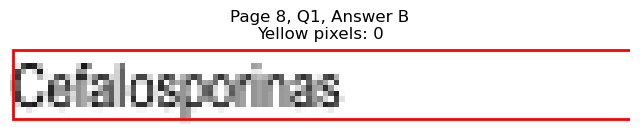

Page 8, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=389.7, y1=114.7
Page 8, Q1, C: Yellow pixels: 1205
Page 8, Q1, C: Total non-white pixels: 1469
Page 8, Q1, C: Yellow percentage: 82.0%


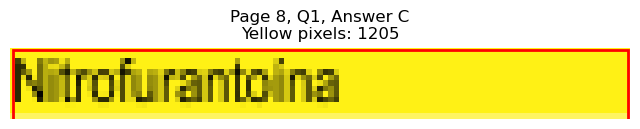

Page 8, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=381.7, y1=127.3
Page 8, Q1, D: Yellow pixels: 105
Page 8, Q1, D: Total non-white pixels: 369
Page 8, Q1, D: Yellow percentage: 28.5%


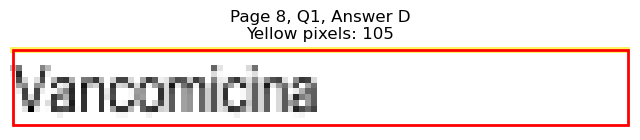


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=161.5, y1=190.4
Page 8, Q2, A: Yellow pixels: 144
Page 8, Q2, A: Total non-white pixels: 642
Page 8, Q2, A: Yellow percentage: 22.4%


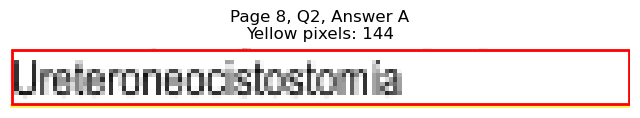

Page 8, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=137.5, y1=203.0
Page 8, Q2, B: Yellow pixels: 1282
Page 8, Q2, B: Total non-white pixels: 1560
Page 8, Q2, B: Yellow percentage: 82.2%


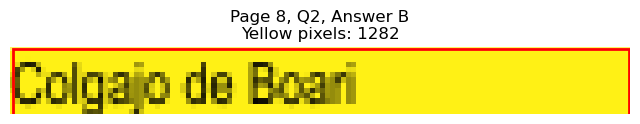

Page 8, Q2 - C: Detected box: x0=327.5, y0=177.7, x1=429.3, y1=190.4
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 513
Page 8, Q2, C: Yellow percentage: 0.0%


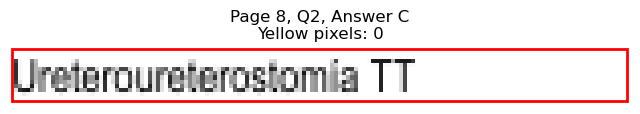

Page 8, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=424.4, y1=203.0
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 479
Page 8, Q2, D: Yellow percentage: 0.0%


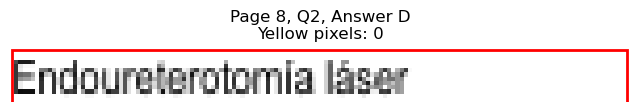


Page 8, Q2 - Selected Answer: B (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=105.9, y1=266.1
Page 8, Q3, A: Yellow pixels: 1013
Page 8, Q3, A: Total non-white pixels: 1232
Page 8, Q3, A: Yellow percentage: 82.2%


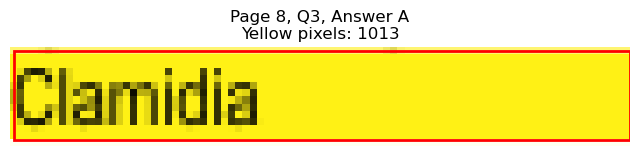

Page 8, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=109.5, y1=278.7
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 331
Page 8, Q3, B: Yellow percentage: 0.0%


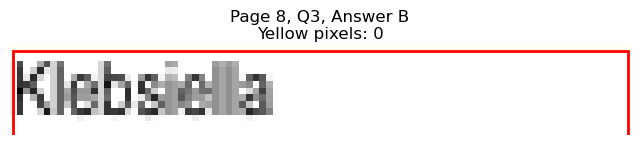

Page 8, Q3 - C: Detected box: x0=327.5, y0=253.5, x1=393.3, y1=266.1
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 346
Page 8, Q3, C: Yellow percentage: 0.0%


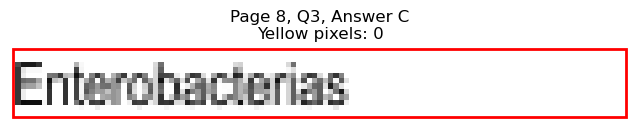

Page 8, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=393.3, y1=278.7
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 346
Page 8, Q3, D: Yellow percentage: 0.0%


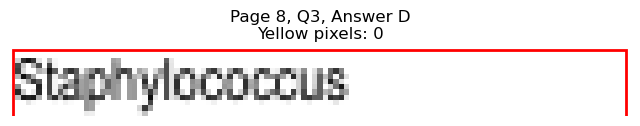


Page 8, Q3 - Selected Answer: A (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=164.7, y1=341.9
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 468
Page 8, Q4, A: Yellow percentage: 0.0%


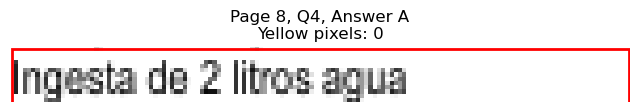

Page 8, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=204.2, y1=354.6
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 626
Page 8, Q4, B: Yellow percentage: 0.0%


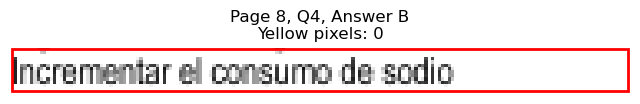

Page 8, Q4 - C: Detected box: x0=327.5, y0=329.2, x1=451.4, y1=341.9
Page 8, Q4, C: Yellow pixels: 1801
Page 8, Q4, C: Total non-white pixels: 2275
Page 8, Q4, C: Yellow percentage: 79.2%


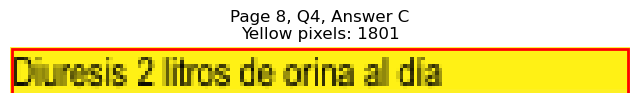

Page 8, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=410.3, y1=354.6
Page 8, Q4, D: Yellow pixels: 134
Page 8, Q4, D: Total non-white pixels: 578
Page 8, Q4, D: Yellow percentage: 23.2%


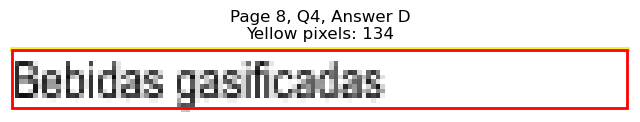


Page 8, Q4 - Selected Answer: C (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=148.1, y1=392.4
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 377
Page 8, Q5, A: Yellow percentage: 0.0%


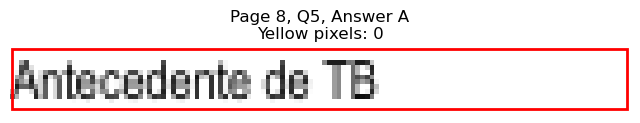

Page 8, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=171.1, y1=405.0
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 487
Page 8, Q5, B: Yellow percentage: 0.0%


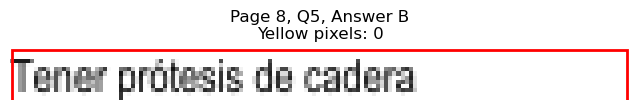

Page 8, Q5 - C: Detected box: x0=327.5, y0=379.7, x1=429.8, y1=392.4
Page 8, Q5, C: Yellow pixels: 1438
Page 8, Q5, C: Total non-white pixels: 2142
Page 8, Q5, C: Yellow percentage: 67.1%


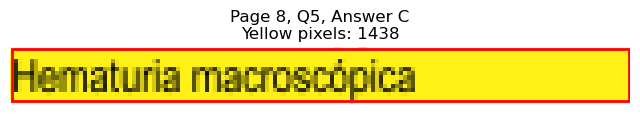

Page 8, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=416.3, y1=405.0
Page 8, Q5, D: Yellow pixels: 0
Page 8, Q5, D: Total non-white pixels: 623
Page 8, Q5, D: Yellow percentage: 0.0%


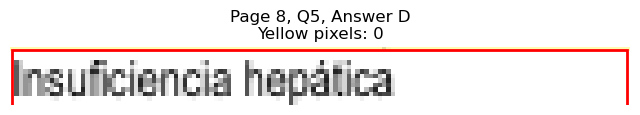


Page 8, Q5 - Selected Answer: C (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=430.2, x1=234.9, y1=442.9
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 1064
Page 8, Q6, A: Yellow percentage: 0.0%


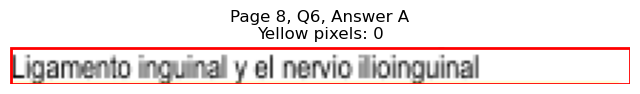

Page 8, Q6 - B: Detected box: x0=68.3, y0=442.8, x1=240.4, y1=455.5
Page 8, Q6, B: Yellow pixels: 2129
Page 8, Q6, B: Total non-white pixels: 2996
Page 8, Q6, B: Yellow percentage: 71.1%


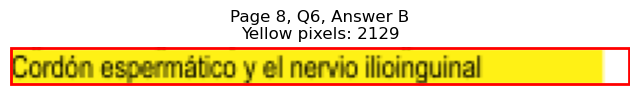

Page 8, Q6 - C: Detected box: x0=327.5, y0=430.2, x1=496.2, y1=442.9
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 812
Page 8, Q6, C: Yellow percentage: 0.0%


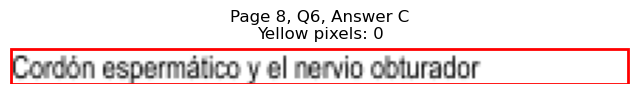

Page 8, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=512.1, y1=455.5
Page 8, Q6, D: Yellow pixels: 0
Page 8, Q6, D: Total non-white pixels: 944
Page 8, Q6, D: Yellow percentage: 0.0%


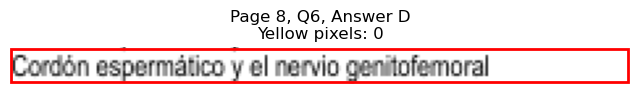


Page 8, Q6 - Selected Answer: B (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=493.4, x1=186.6, y1=506.0
Page 8, Q7, A: Yellow pixels: 1695
Page 8, Q7, A: Total non-white pixels: 2203
Page 8, Q7, A: Yellow percentage: 76.9%


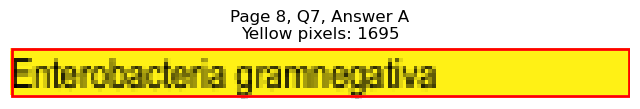

Page 8, Q7 - B: Detected box: x0=68.3, y0=506.0, x1=127.9, y1=518.6
Page 8, Q7, B: Yellow pixels: 102
Page 8, Q7, B: Total non-white pixels: 430
Page 8, Q7, B: Yellow percentage: 23.7%


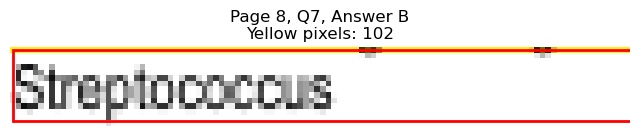

Page 8, Q7 - C: Detected box: x0=327.5, y0=493.4, x1=368.7, y1=506.0
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 231
Page 8, Q7, C: Yellow percentage: 0.0%


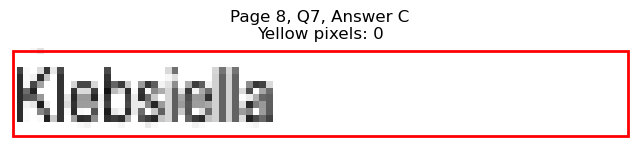

Page 8, Q7 - D: Detected box: x0=327.5, y0=506.0, x1=361.1, y1=518.6
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 167
Page 8, Q7, D: Yellow percentage: 0.0%


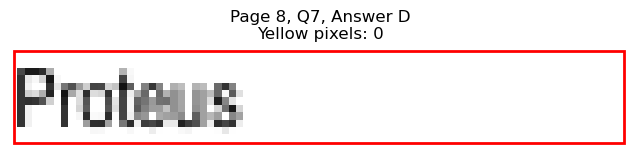


Page 8, Q7 - Selected Answer: A (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=56.6, y0=543.8, x1=65.2, y1=556.4
Page 8, Q8, A: Yellow pixels: 731
Page 8, Q8, A: Total non-white pixels: 840
Page 8, Q8, A: Yellow percentage: 87.0%


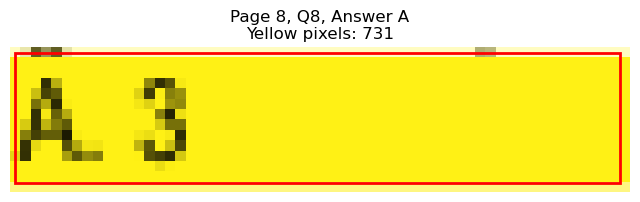

Page 8, Q8 - B: Detected box: x0=56.6, y0=556.5, x1=65.2, y1=569.2
Page 8, Q8, B: Yellow pixels: 60
Page 8, Q8, B: Total non-white pixels: 120
Page 8, Q8, B: Yellow percentage: 50.0%


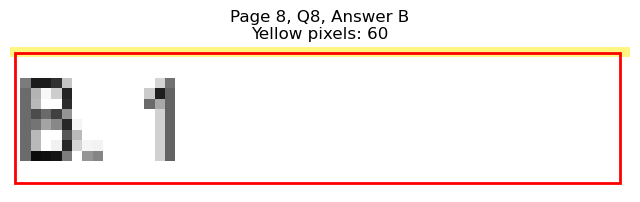

Page 8, Q8 - C: Detected box: x0=315.4, y0=543.8, x1=324.4, y1=556.4
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 73
Page 8, Q8, C: Yellow percentage: 0.0%


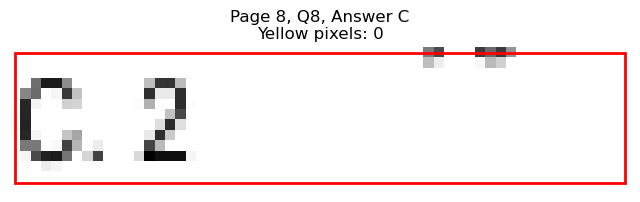

Page 8, Q8 - D: Detected box: x0=315.4, y0=556.5, x1=324.4, y1=569.2
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 69
Page 8, Q8, D: Yellow percentage: 0.0%


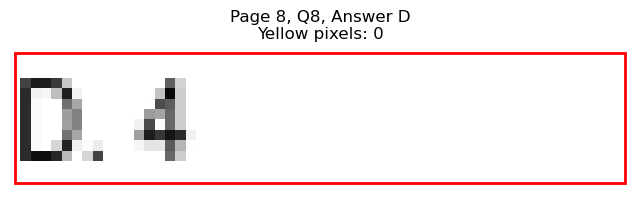


Page 8, Q8 - Selected Answer: A (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=619.6, x1=139.9, y1=632.3
Page 8, Q9, A: Yellow pixels: 1182
Page 8, Q9, A: Total non-white pixels: 1708
Page 8, Q9, A: Yellow percentage: 69.2%


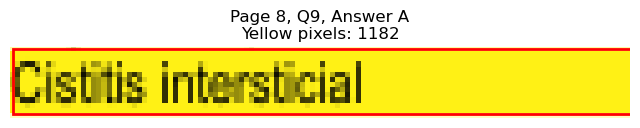

Page 8, Q9 - B: Detected box: x0=68.3, y0=632.2, x1=130.9, y1=644.9
Page 8, Q9, B: Yellow pixels: 0
Page 8, Q9, B: Total non-white pixels: 445
Page 8, Q9, B: Yellow percentage: 0.0%


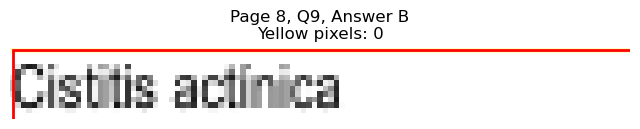

Page 8, Q9 - C: Detected box: x0=327.5, y0=619.6, x1=387.8, y1=632.3
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 303
Page 8, Q9, C: Yellow percentage: 0.0%


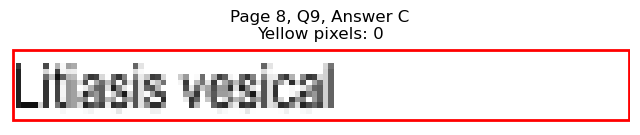

Page 8, Q9 - D: Detected box: x0=327.5, y0=632.2, x1=402.8, y1=644.9
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 385
Page 8, Q9, D: Yellow percentage: 0.0%


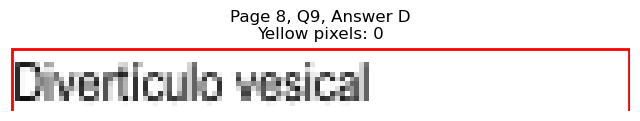


Page 8, Q9 - Selected Answer: A (based on yellow pixel count)




Page 8, Q10 - A: Detected box: x0=68.3, y0=670.1, x1=144.0, y1=682.7
Page 8, Q10, A: Yellow pixels: 0
Page 8, Q10, A: Total non-white pixels: 405
Page 8, Q10, A: Yellow percentage: 0.0%


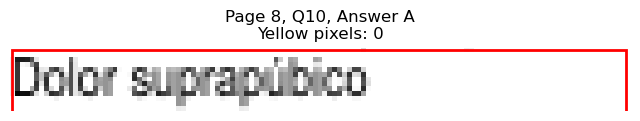

Page 8, Q10 - B: Detected box: x0=68.3, y0=682.7, x1=138.5, y1=695.3
Page 8, Q10, B: Yellow pixels: 0
Page 8, Q10, B: Total non-white pixels: 341
Page 8, Q10, B: Yellow percentage: 0.0%


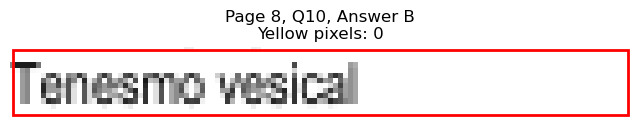

Page 8, Q10 - C: Detected box: x0=327.5, y0=670.1, x1=358.1, y1=682.7
Page 8, Q10, C: Yellow pixels: 0
Page 8, Q10, C: Total non-white pixels: 236
Page 8, Q10, C: Yellow percentage: 0.0%


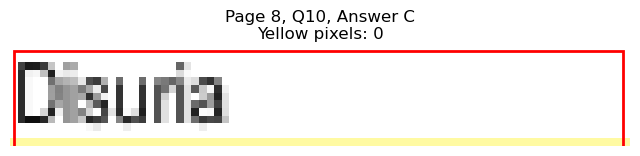

Page 8, Q10 - D: Detected box: x0=327.5, y0=682.7, x1=371.7, y1=695.3
Page 8, Q10, D: Yellow pixels: 956
Page 8, Q10, D: Total non-white pixels: 1330
Page 8, Q10, D: Yellow percentage: 71.9%


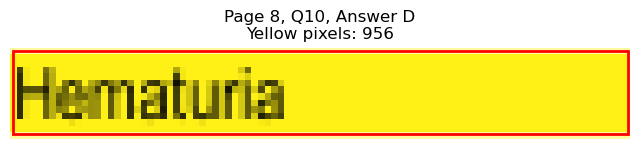


Page 8, Q10 - Selected Answer: D (based on yellow pixel count)




Page 8, Q11 - A: Detected box: x0=68.3, y0=733.2, x1=171.1, y1=745.8
Page 8, Q11, A: Yellow pixels: 0
Page 8, Q11, A: Total non-white pixels: 533
Page 8, Q11, A: Yellow percentage: 0.0%


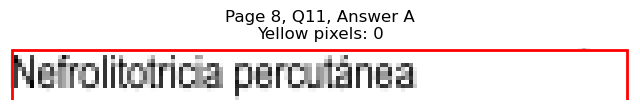

Page 8, Q11 - B: Detected box: x0=68.3, y0=745.8, x1=127.0, y1=758.4
Page 8, Q11, B: Yellow pixels: 0
Page 8, Q11, B: Total non-white pixels: 312
Page 8, Q11, B: Yellow percentage: 0.0%


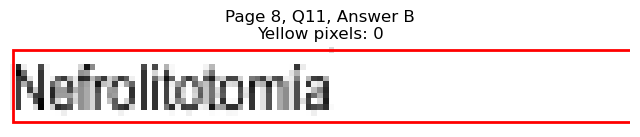

Page 8, Q11 - C: Detected box: x0=327.5, y0=733.2, x1=386.7, y1=745.8
Page 8, Q11, C: Yellow pixels: 0
Page 8, Q11, C: Total non-white pixels: 418
Page 8, Q11, C: Yellow percentage: 0.0%


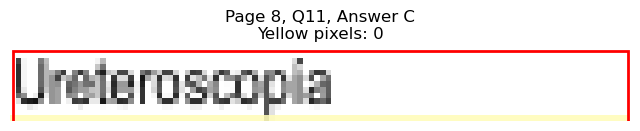

Page 8, Q11 - D: Detected box: x0=327.5, y0=745.8, x1=510.6, y1=758.4
Page 8, Q11, D: Yellow pixels: 2076
Page 8, Q11, D: Total non-white pixels: 2996
Page 8, Q11, D: Yellow percentage: 69.3%


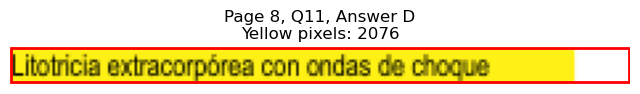


Page 8, Q11 - Selected Answer: D (based on yellow pixel count)





Page 9: Found 7 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=109.9, y1=127.3
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 174
Page 9, Q1, A: Yellow percentage: 0.0%


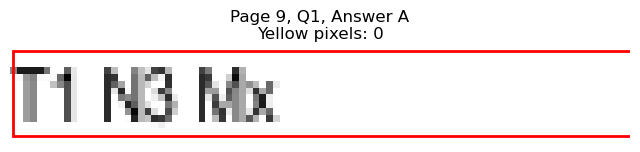

Page 9, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=110.4, y1=139.9
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 191
Page 9, Q1, B: Yellow percentage: 0.0%


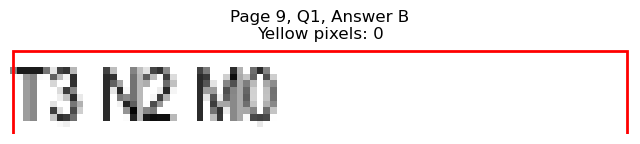

Page 9, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=369.2, y1=127.3
Page 9, Q1, C: Yellow pixels: 93
Page 9, Q1, C: Total non-white pixels: 275
Page 9, Q1, C: Yellow percentage: 33.8%


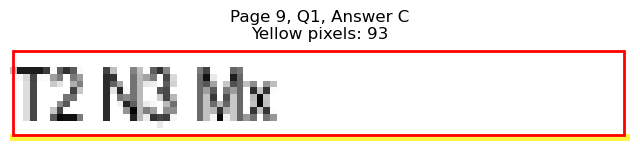

Page 9, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=369.7, y1=139.9
Page 9, Q1, D: Yellow pixels: 1048
Page 9, Q1, D: Total non-white pixels: 1209
Page 9, Q1, D: Yellow percentage: 86.7%


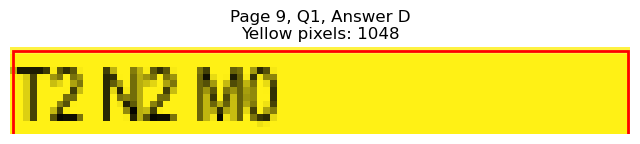


Page 9, Q1 - Selected Answer: D (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=109.5, y1=177.8
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 239
Page 9, Q2, A: Yellow percentage: 0.0%


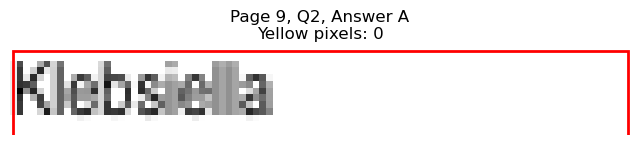

Page 9, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=121.5, y1=190.4
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 293
Page 9, Q2, B: Yellow percentage: 0.0%


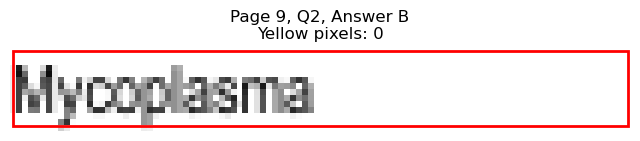

Page 9, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=361.1, y1=177.8
Page 9, Q2, C: Yellow pixels: 979
Page 9, Q2, C: Total non-white pixels: 1105
Page 9, Q2, C: Yellow percentage: 88.6%


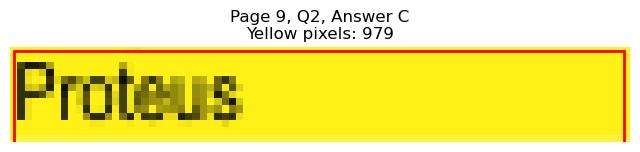

Page 9, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=387.8, y1=190.4
Page 9, Q2, D: Yellow pixels: 111
Page 9, Q2, D: Total non-white pixels: 416
Page 9, Q2, D: Yellow percentage: 26.7%


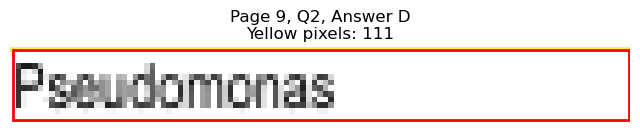


Page 9, Q2 - Selected Answer: C (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=148.8, y1=228.3
Page 9, Q3, A: Yellow pixels: 131
Page 9, Q3, A: Total non-white pixels: 487
Page 9, Q3, A: Yellow percentage: 26.9%


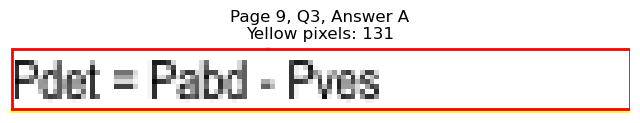

Page 9, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=148.8, y1=240.9
Page 9, Q3, B: Yellow pixels: 1437
Page 9, Q3, B: Total non-white pixels: 1703
Page 9, Q3, B: Yellow percentage: 84.4%


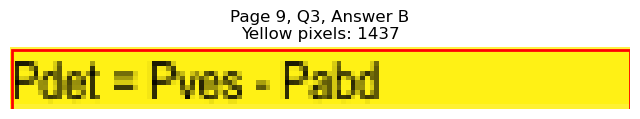

Page 9, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=406.5, y1=228.3
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 339
Page 9, Q3, C: Yellow percentage: 0.0%


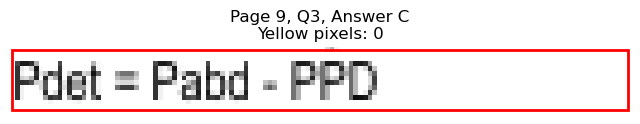

Page 9, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=405.5, y1=240.9
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 332
Page 9, Q3, D: Yellow percentage: 0.0%


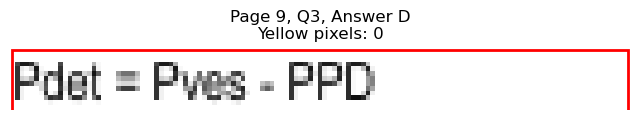


Page 9, Q3 - Selected Answer: B (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=266.1, x1=115.5, y1=278.7
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 223
Page 9, Q4, A: Yellow percentage: 0.0%


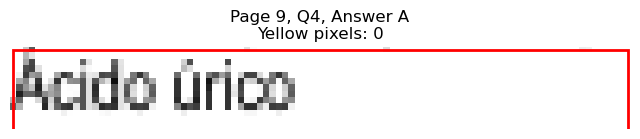

Page 9, Q4 - B: Detected box: x0=68.3, y0=278.8, x1=140.1, y1=291.5
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 361
Page 9, Q4, B: Yellow percentage: 0.0%


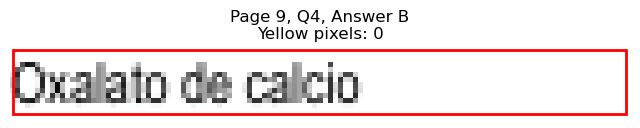

Page 9, Q4 - C: Detected box: x0=327.5, y0=266.1, x1=365.1, y1=278.7
Page 9, Q4, C: Yellow pixels: 1019
Page 9, Q4, C: Total non-white pixels: 1157
Page 9, Q4, C: Yellow percentage: 88.1%


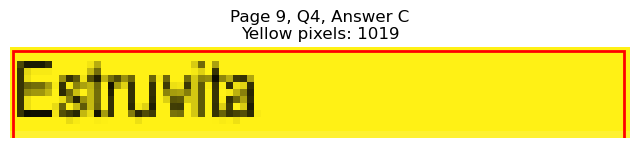

Page 9, Q4 - D: Detected box: x0=327.5, y0=278.8, x1=360.2, y1=291.5
Page 9, Q4, D: Yellow pixels: 84
Page 9, Q4, D: Total non-white pixels: 245
Page 9, Q4, D: Yellow percentage: 34.3%


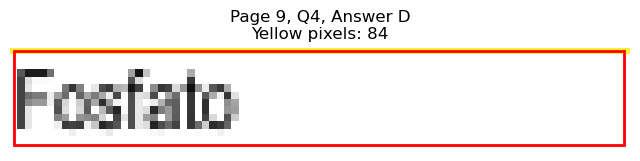


Page 9, Q4 - Selected Answer: C (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=329.2, x1=157.6, y1=341.9
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 451
Page 9, Q5, A: Yellow percentage: 0.0%


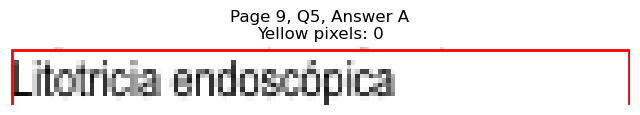

Page 9, Q5 - B: Detected box: x0=68.3, y0=341.9, x1=171.1, y1=354.6
Page 9, Q5, B: Yellow pixels: 1590
Page 9, Q5, B: Total non-white pixels: 2156
Page 9, Q5, B: Yellow percentage: 73.7%


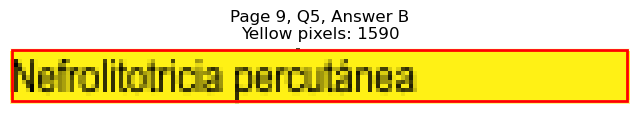

Page 9, Q5 - C: Detected box: x0=327.5, y0=329.2, x1=421.9, y1=341.9
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 457
Page 9, Q5, C: Yellow percentage: 0.0%


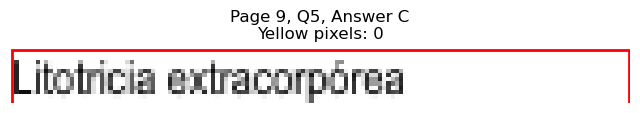

Page 9, Q5 - D: Detected box: x0=327.5, y0=341.9, x1=444.4, y1=354.6
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 602
Page 9, Q5, D: Yellow percentage: 0.0%


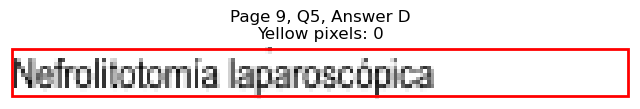


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=392.3, x1=138.0, y1=405.0
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 444
Page 9, Q6, A: Yellow percentage: 0.0%


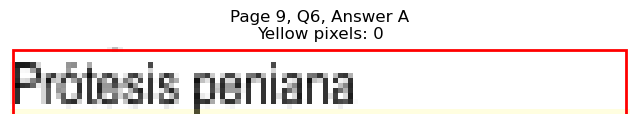

Page 9, Q6 - B: Detected box: x0=68.3, y0=404.9, x1=142.0, y1=417.6
Page 9, Q6, B: Yellow pixels: 1304
Page 9, Q6, B: Total non-white pixels: 1736
Page 9, Q6, B: Yellow percentage: 75.1%


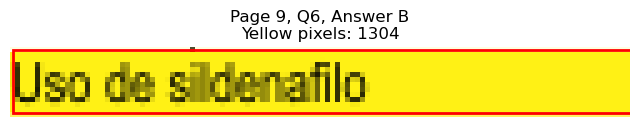

Page 9, Q6 - C: Detected box: x0=327.5, y0=392.3, x1=394.3, y1=405.0
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 336
Page 9, Q6, C: Yellow percentage: 0.0%


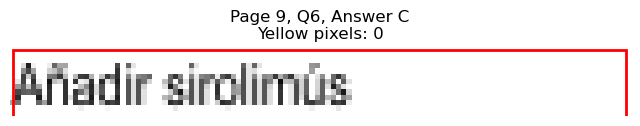

Page 9, Q6 - D: Detected box: x0=327.5, y0=404.9, x1=433.9, y1=417.6
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 547
Page 9, Q6, D: Yellow percentage: 0.0%


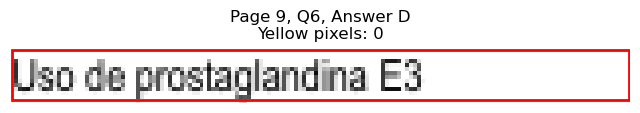


Page 9, Q6 - Selected Answer: B (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=442.8, x1=112.5, y1=455.5
Page 9, Q7, A: Yellow pixels: 95
Page 9, Q7, A: Total non-white pixels: 326
Page 9, Q7, A: Yellow percentage: 29.1%


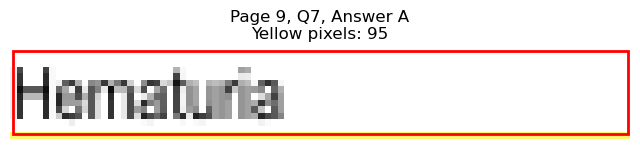

Page 9, Q7 - B: Detected box: x0=68.3, y0=455.5, x1=143.1, y1=468.1
Page 9, Q7, B: Yellow pixels: 1332
Page 9, Q7, B: Total non-white pixels: 1764
Page 9, Q7, B: Yellow percentage: 75.5%


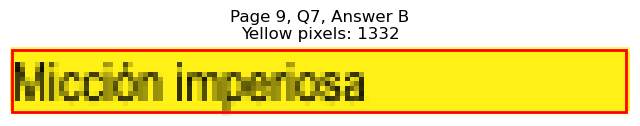

Page 9, Q7 - C: Detected box: x0=327.5, y0=442.8, x1=361.1, y1=455.5
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 168
Page 9, Q7, C: Yellow percentage: 0.0%


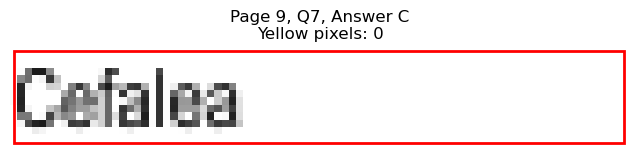

Page 9, Q7 - D: Detected box: x0=327.5, y0=455.5, x1=355.6, y1=468.1
Page 9, Q7, D: Yellow pixels: 0
Page 9, Q7, D: Total non-white pixels: 145
Page 9, Q7, D: Yellow percentage: 0.0%


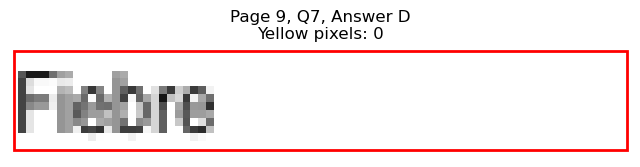


Page 9, Q7 - Selected Answer: B (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,¿Cuál de las siguientes patologías causa hiper...
1,"Varón de 16 años. TE 2 horas, acude a EMG por ..."
2,"¿Cuál es una contraindicación absoluta, para r..."
3,¿Cuál es el medicamento estándar para el trata...
4,"En el adenocarcinoma de próstata, el sistema d..."
...,...
95,Para calcular la presión del detrusor (Pdet) e...
96,¿Cuál es el principal componente del cálculo c...
97,"Varón de 28 años, con obesidad mórbida. UROTEM..."
98,"Varón de 34 años, trasplantado renal, tuvo una..."


In [8]:
answers_df

,option_A,option_B,option_C,option_D
0,Lesión medular,Tumor vesical,Litiasis vesical,Envejecimiento
1,Epididimitis aguda,Hidrocele,Torsión testicular,Infección urinaria
2,Portador de sonda Foley,Edad avanzada,Estrechez uretral,Prostatitis aguda
3,Goserelina,Docetaxel,Bicalutamida,Cabazitaxel
4,la célula muscular lisa.,el patrón glandular del tumor.,células de la cápsula prostática.,células de la matriz celular.
...,...,...,...,...
95,Pdet = Pabd - Pves,Pdet = Pves - Pabd,Pdet = Pabd - PPD,Pdet = Pves - PPD
96,Ácido úrico,Oxalato de calcio,Estruvita,Fosfato
97,Litotricia endoscópica,Nefrolitotricia percutánea,Litotricia extracorpórea,Nefrolitotomía laparoscópica
98,Prótesis peniana,Uso de sildenafilo,Añadir sirolimús,Uso de prostaglandina E3


In [9]:
correct_answers_df

,correct_answer
0,A
1,C
2,D
3,B
4,B
...,...
95,B
96,C
97,B
98,B


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,correct_answer
0,¿Cuál de las siguientes patologías causa hiper...,Lesión medular,Tumor vesical,Litiasis vesical,Envejecimiento,A
1,"Varón de 16 años. TE 2 horas, acude a EMG por ...",Epididimitis aguda,Hidrocele,Torsión testicular,Infección urinaria,C
2,"¿Cuál es una contraindicación absoluta, para r...",Portador de sonda Foley,Edad avanzada,Estrechez uretral,Prostatitis aguda,D
3,¿Cuál es el medicamento estándar para el trata...,Goserelina,Docetaxel,Bicalutamida,Cabazitaxel,B
4,"En el adenocarcinoma de próstata, el sistema d...",la célula muscular lisa.,el patrón glandular del tumor.,células de la cápsula prostática.,células de la matriz celular.,B
...,...,...,...,...,...,...
95,Para calcular la presión del detrusor (Pdet) e...,Pdet = Pabd - Pves,Pdet = Pves - Pabd,Pdet = Pabd - PPD,Pdet = Pves - PPD,B
96,¿Cuál es el principal componente del cálculo c...,Ácido úrico,Oxalato de calcio,Estruvita,Fosfato,C
97,"Varón de 28 años, con obesidad mórbida. UROTEM...",Litotricia endoscópica,Nefrolitotricia percutánea,Litotricia extracorpórea,Nefrolitotomía laparoscópica,B
98,"Varón de 34 años, trasplantado renal, tuvo una...",Prótesis peniana,Uso de sildenafilo,Añadir sirolimús,Uso de prostaglandina E3,B


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/UROLOGÍA.csv
